In [1]:
!pip install -q mesa==3.5.2 numpy pandas matplotlib seaborn scipy

# **Importing Required Libraries**

In [2]:
# General libraries
import random
import numpy as np
import pandas as pd

# Visualisation libraries
import matplotlib.pyplot as plt
import networkx as nx
import seaborn as sns

# Statistical libraries
from scipy import stats

# Mesa agent-based modelling
import mesa
from mesa import Agent
from mesa import Model
from mesa.datacollection import DataCollector

# Reinforcement Learning libraries
from collections import defaultdict

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Graph style
plt.style.use("ggplot")

# Displaying Mesa version
print("Mesa Version:", mesa.__version__)

Mesa Version: 3.5.2


# **Loading Datasets**

In [3]:
# Government Borrowing
debt = pd.read_csv("series-230626.csv")

# Bond Yield
bond = pd.read_csv("BoE-Database_export.csv")

# World Bank Dataset
macro = pd.read_csv(
    "API_GBR_DS2_en_csv_v2_448313.csv",
    skiprows=4
)

print("Debt Shape :", debt.shape)
print("Bond Shape :", bond.shape)
print("Macro Shape:", macro.shape)

Debt Shape : (574, 2)
Bond Shape : (42, 2)
Macro Shape: (1486, 71)


# **Datsets Overview**

In [4]:
print("\nDebt Dataset")
display(debt.head())

print("\nBond Dataset")
display(bond.head())

print("\nWorld Bank Dataset")
display(macro.head())


Debt Dataset


,Title,"Public sector net borrowing, excluding public sector banks (£ million)"
0,CDID,DZLS
1,Source dataset ID,PUSF
2,PreUnit,£
3,Unit,million
4,Release date,19-06-2026



Bond Dataset


,Date,Value
0,31-12-1984,11.4319
1,31-12-1985,11.1617
2,31-12-1986,10.2052
3,31-12-1987,9.7182
4,31-12-1988,9.7938



World Bank Dataset


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,United Kingdom,GBR,"Unemployment, male (% of male labor force) (mo...",SL.UEM.TOTL.MA.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.624,4.217,3.835,4.760,5.083,3.911,4.335,4.568,5.058,NaN
1,United Kingdom,GBR,"Share of youth not in education, employment or...",SL.UEM.NEET.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,12.261,12.333,12.335,12.607,11.410,11.809,12.802,14.300,14.404,NaN
2,United Kingdom,GBR,"Share of youth not in education, employment or...",SL.UEM.NEET.FE.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,12.267,13.037,12.155,11.916,10.490,11.070,12.122,13.090,13.613,NaN
3,United Kingdom,GBR,"Unemployment with intermediate education, fema...",SL.UEM.INTM.FE.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.650,4.372,3.569,4.483,4.766,4.535,4.975,5.286,5.536,NaN
4,United Kingdom,GBR,Unemployment with advanced education (% of tot...,SL.UEM.ADVN.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,2.733,2.595,2.344,3.238,3.278,2.346,2.598,2.733,3.367,NaN


## **Datsets Information**

In [5]:
print("\nDebt Info")
debt.info()

print("\nBond Info")
bond.info()

print("\nMacro Info")
macro.info()


Debt Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574 entries, 0 to 573
Data columns (total 2 columns):
 #   Column                                                                  Non-Null Count  Dtype 
---  ------                                                                  --------------  ----- 
 0   Title                                                                   574 non-null    object
 1   Public sector net borrowing, excluding public sector banks (£ million)  501 non-null    object
dtypes: object(2)
memory usage: 9.1+ KB

Bond Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    42 non-null     object 
 1   Value   42 non-null     float64
dtypes: float64(1), object(1)
memory usage: 804.0+ bytes

Macro Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1486 entries, 0 to 1485
Data columns (total 71 columns):
 #   Col

## **Missing vlaue Checking for Each Datasets**

In [6]:
print("\nMissing Values")

print(debt.isnull().sum())

print(bond.isnull().sum())

print(macro.isnull().sum())


Missing Values
Title                                                                      0
Public sector net borrowing, excluding public sector banks (£ million)    73
dtype: int64
Date     0
Value    0
dtype: int64
Country Name         0
Country Code         0
Indicator Name       0
Indicator Code       0
1960              1311
                  ... 
2022               673
2023               738
2024               865
2025              1360
Unnamed: 70       1486
Length: 71, dtype: int64


## **Duplicate Value Checking**

In [7]:
print("\nDuplicates")

print("Debt :", debt.duplicated().sum())

print("Bond :", bond.duplicated().sum())

print("Macro :", macro.duplicated().sum())


Duplicates
Debt : 0
Bond : 0
Macro : 0


# **Data Cleaning**

## **Government Borrowing Data Cleaning**

In [8]:
debt.columns=["Year","Government_Borrowing"]

debt=debt[
    debt["Year"].astype(str).str.match(r"^\d{4}$")
]

debt["Year"]=debt["Year"].astype(int)

debt["Government_Borrowing"]=pd.to_numeric(
    debt["Government_Borrowing"],
    errors="coerce"
)

debt=debt.dropna()

debt.reset_index(drop=True,inplace=True)

display(debt.head())

,Year,Government_Borrowing
0,1997,19381.0
1,1998,3875.0
2,1999,-7654.0
3,2000,-16426.0
4,2001,-3107.0


## **Bond Yield Data Cleaning**

In [9]:
bond.columns=["Date","Bond_Yield"]

bond["Date"]=pd.to_datetime(
    bond["Date"],
    dayfirst=True
)

bond["Year"]=bond["Date"].dt.year

bond_yearly=(
    bond.groupby("Year")
    ["Bond_Yield"]
    .mean()
    .reset_index()
)

display(bond_yearly.head())

,Year,Bond_Yield
0,1984,11.4319
1,1985,11.1617
2,1986,10.2052
3,1987,9.7182
4,1988,9.7938


## **World Bank Indicator Selection**

In [10]:
print("Number of Indicators :", macro["Indicator Name"].nunique())

display(
    macro[["Indicator Name","Indicator Code"]]
    .drop_duplicates()
    .sort_values("Indicator Name")
)

Number of Indicators : 1486


,Indicator Name,Indicator Code
879,ARI treatment (% of children under 5 taken to ...,SH.STA.ARIC.ZS
1087,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.ZS
726,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.RU.ZS
1450,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.UR.ZS
1086,Access to electricity (% of population),EG.ELC.ACCS.ZS
...,...,...
1363,Women who believe a husband is justified in be...,SG.VAW.REFU.ZS
786,Women who were first married by age 15 (% of w...,SP.M15.2024.FE.ZS
168,Women who were first married by age 18 (% of w...,SP.M18.2024.FE.ZS
1357,Women's share of population ages 15+ living wi...,SH.DYN.AIDS.FE.ZS


## **Extracting Required Indicators**

In [11]:
required = [

    "GDP (current US$)",

    "Inflation, consumer prices (annual %)",

    "Unemployment, total (% of total labor force) (modeled ILO estimate)",

    "Population, total",

    "General government final consumption expenditure (% of GDP)"

]

macro = macro[
    macro["Indicator Name"].isin(required)
]

print(macro.shape)

display(macro.head())

(5, 71)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
369,United Kingdom,GBR,"Population, total",SP.POP.TOTL,5.240000e+07,5.280000e+07,5.325000e+07,5.365000e+07,5.400000e+07,5.434805e+07,...,6.596600e+07,6.628900e+07,6.663100e+07,6.674400e+07,6.698400e+07,6.760400e+07,6.849200e+07,6.922600e+07,NaN,NaN
406,United Kingdom,GBR,GDP (current US$),NY.GDP.MKTP.CD,7.323397e+10,7.774197e+10,8.124756e+10,8.656196e+10,9.440756e+10,1.018248e+11,...,2.699118e+12,2.897028e+12,2.875710e+12,2.724001e+12,3.194559e+12,3.181244e+12,3.420797e+12,3.686033e+12,NaN,NaN
985,United Kingdom,GBR,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1.003576e+00,3.447496e+00,4.196499e+00,2.018544e+00,3.281587e+00,4.773775e+00,...,2.557756e+00,2.292840e+00,1.738105e+00,9.894867e-01,2.518371e+00,7.922049e+00,6.793967e+00,3.271573e+00,NaN,NaN
1008,United Kingdom,GBR,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.501000e+00,4.145000e+00,3.657000e+00,4.472000e+00,4.864000e+00,3.768000e+00,4.025000e+00,4.361000e+00,4.746,NaN
1305,United Kingdom,GBR,General government final consumption expenditu...,NE.CON.GOVT.ZS,1.756838e+01,1.759395e+01,1.791202e+01,1.721476e+01,1.681183e+01,1.760877e+01,...,1.852818e+01,1.837689e+01,1.893473e+01,2.238497e+01,2.190238e+01,2.038754e+01,2.024138e+01,NaN,NaN,NaN


In [12]:
# REQUIRED YEARS

years = [str(i) for i in range(1997,2026)]

columns = [

    "Indicator Name"

] + years

macro = macro[columns]

display(macro.head())

,Indicator Name,1997,1998,1999,2000,2001,2002,2003,2004,2005,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
369,"Population, total",5.831695e+07,5.848714e+07,5.868247e+07,5.889251e+07,5.911967e+07,5.937048e+07,5.964758e+07,5.998790e+07,6.040121e+07,...,6.560700e+07,6.596600e+07,6.628900e+07,6.663100e+07,6.674400e+07,6.698400e+07,6.760400e+07,6.849200e+07,6.922600e+07,NaN
406,GDP (current US$),1.569317e+12,1.660821e+12,1.693459e+12,1.671598e+12,1.656171e+12,1.790537e+12,2.061228e+12,2.429775e+12,2.551362e+12,...,2.706808e+12,2.699118e+12,2.897028e+12,2.875710e+12,2.724001e+12,3.194559e+12,3.181244e+12,3.420797e+12,3.686033e+12,NaN
985,"Inflation, consumer prices (annual %)",2.201143e+00,1.820562e+00,1.752951e+00,1.182956e+00,1.532350e+00,1.520402e+00,1.376500e+00,1.390398e+00,2.089136e+00,...,1.008417e+00,2.557756e+00,2.292840e+00,1.738105e+00,9.894867e-01,2.518371e+00,7.922049e+00,6.793967e+00,3.271573e+00,NaN
1008,"Unemployment, total (% of total labor force) (...",7.072000e+00,6.198000e+00,6.042000e+00,5.558000e+00,4.696000e+00,5.037000e+00,4.807000e+00,4.594000e+00,4.884000e+00,...,4.909000e+00,4.501000e+00,4.145000e+00,3.657000e+00,4.472000e+00,4.864000e+00,3.768000e+00,4.025000e+00,4.361000e+00,4.746
1305,General government final consumption expenditu...,1.595678e+01,1.597092e+01,1.639835e+01,1.658054e+01,1.719737e+01,1.809005e+01,1.877597e+01,1.933416e+01,1.953459e+01,...,1.909261e+01,1.852818e+01,1.837689e+01,1.893473e+01,2.238497e+01,2.190238e+01,2.038754e+01,2.024138e+01,NaN,NaN


## **Transpose Dataset**

In [13]:
macro = macro.set_index("Indicator Name")

macro = macro.T

macro.reset_index(inplace=True)

macro.rename(
    columns={"index":"Year"},
    inplace=True
)

display(macro.head())

Indicator Name,Year,"Population, total",GDP (current US$),"Inflation, consumer prices (annual %)","Unemployment, total (% of total labor force) (modeled ILO estimate)",General government final consumption expenditure (% of GDP)
0,1997,58316954.0,1.569317e+12,2.201143,7.072,15.956784
1,1998,58487141.0,1.660821e+12,1.820562,6.198,15.970918
2,1999,58682466.0,1.693459e+12,1.752951,6.042,16.398354
3,2000,58892514.0,1.671598e+12,1.182956,5.558,16.580539
4,2001,59119673.0,1.656171e+12,1.532350,4.696,17.197373


## **Renaming Columns**

In [14]:
macro.rename(columns={
    "GDP (current US$)": "GDP",
    "Inflation, consumer prices (annual %)": "Inflation",
    "Unemployment, total (% of total labor force) (modeled ILO estimate)": "Unemployment",
    "Population, total": "Population",
    "General government final consumption expenditure (% of GDP)": "Government_Expenditure"
}, inplace=True)

display(macro.head())

Indicator Name,Year,Population,GDP,Inflation,Unemployment,Government_Expenditure
0,1997,58316954.0,1.569317e+12,2.201143,7.072,15.956784
1,1998,58487141.0,1.660821e+12,1.820562,6.198,15.970918
2,1999,58682466.0,1.693459e+12,1.752951,6.042,16.398354
3,2000,58892514.0,1.671598e+12,1.182956,5.558,16.580539
4,2001,59119673.0,1.656171e+12,1.532350,4.696,17.197373


# **Converting data**

In [15]:
macro["Year"] = macro["Year"].astype(int)

for col in macro.columns[1:]:

    macro[col] = pd.to_numeric(

        macro[col],

        errors="coerce"

    )

print(macro.info())

display(macro.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Year                    29 non-null     int64  
 1   Population              28 non-null     float64
 2   GDP                     28 non-null     float64
 3   Inflation               28 non-null     float64
 4   Unemployment            29 non-null     float64
 5   Government_Expenditure  27 non-null     float64
dtypes: float64(5), int64(1)
memory usage: 1.5 KB
None


Indicator Name,Year,Population,GDP,Inflation,Unemployment,Government_Expenditure
0,1997,58316954.0,1.569317e+12,2.201143,7.072,15.956784
1,1998,58487141.0,1.660821e+12,1.820562,6.198,15.970918
2,1999,58682466.0,1.693459e+12,1.752951,6.042,16.398354
3,2000,58892514.0,1.671598e+12,1.182956,5.558,16.580539
4,2001,59119673.0,1.656171e+12,1.532350,4.696,17.197373


## **Handling Missing Values**

In [16]:
print(macro.isnull().sum())

macro = macro.ffill().bfill()

print("Missing values after imputation:")
print(macro.isnull().sum())

Indicator Name
Year                      0
Population                1
GDP                       1
Inflation                 1
Unemployment              0
Government_Expenditure    2
dtype: int64
Missing values after imputation:
Indicator Name
Year                      0
Population                0
GDP                       0
Inflation                 0
Unemployment              0
Government_Expenditure    0
dtype: int64


# **Merging all Three datasets**

In [17]:
master = debt.merge(

    bond_yearly,

    on="Year",

    how="inner"

)

master = master.merge(

    macro,

    on="Year",

    how="inner"

)

print(master.shape)

display(master.head())

display(master.tail())

(29, 8)


,Year,Government_Borrowing,Bond_Yield,Population,GDP,Inflation,Unemployment,Government_Expenditure
0,1997,19381.0,7.0491,58316954.0,1.569317e+12,2.201143,7.072,15.956784
1,1998,3875.0,5.5465,58487141.0,1.660821e+12,1.820562,6.198,15.970918
2,1999,-7654.0,5.1028,58682466.0,1.693459e+12,1.752951,6.042,16.398354
3,2000,-16426.0,5.3289,58892514.0,1.671598e+12,1.182956,5.558,16.580539
4,2001,-3107.0,4.9279,59119673.0,1.656171e+12,1.532350,4.696,17.197373


,Year,Government_Borrowing,Bond_Yield,Population,GDP,Inflation,Unemployment,Government_Expenditure
24,2021,161122.0,0.7898,66984000.0,3.194559e+12,2.518371,4.864,21.902377
25,2022,108131.0,2.4532,67604000.0,3.181244e+12,7.922049,3.768,20.387540
26,2023,143576.0,4.0692,68492000.0,3.420797e+12,6.793967,4.025,20.241381
27,2024,152004.0,4.1430,69226000.0,3.686033e+12,3.271573,4.361,20.241381
28,2025,147593.0,4.5833,69226000.0,3.686033e+12,3.271573,4.746,20.241381


In [18]:
# Preparing historical economic data for simulation
economic_data = master.sort_values("Year").reset_index(drop=True)

economic_data = economic_data[
    [
        "Year",
        "Government_Borrowing",
        "Bond_Yield",
        "GDP",
        "Inflation",
        "Unemployment",
        "Population",
        "Government_Expenditure"
    ]
].copy()

# Converting economic variables to numeric
economic_columns = [
    "Government_Borrowing",
    "Bond_Yield",
    "GDP",
    "Inflation",
    "Unemployment",
    "Population",
    "Government_Expenditure"
]

for col in economic_columns:
    economic_data[col] = pd.to_numeric(
        economic_data[col], errors="coerce"
    )

economic_data = economic_data.ffill().bfill()

print("Historical economic data prepared:", economic_data.shape)
display(economic_data.head())

Historical economic data prepared: (29, 8)


,Year,Government_Borrowing,Bond_Yield,GDP,Inflation,Unemployment,Population,Government_Expenditure
0,1997,19381.0,7.0491,1.569317e+12,2.201143,7.072,58316954.0,15.956784
1,1998,3875.0,5.5465,1.660821e+12,1.820562,6.198,58487141.0,15.970918
2,1999,-7654.0,5.1028,1.693459e+12,1.752951,6.042,58682466.0,16.398354
3,2000,-16426.0,5.3289,1.671598e+12,1.182956,5.558,58892514.0,16.580539
4,2001,-3107.0,4.9279,1.656171e+12,1.532350,4.696,59119673.0,17.197373


## **Saving Merging Final Dataset**

In [19]:
master.to_csv("master_dataset.csv", index=False)

## **Dtaset Information**

In [20]:
print(master.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Year                    29 non-null     int64  
 1   Government_Borrowing    29 non-null     float64
 2   Bond_Yield              29 non-null     float64
 3   Population              29 non-null     float64
 4   GDP                     29 non-null     float64
 5   Inflation               29 non-null     float64
 6   Unemployment            29 non-null     float64
 7   Government_Expenditure  29 non-null     float64
dtypes: float64(7), int64(1)
memory usage: 1.9 KB
None


In [21]:
master.describe()

,Year,Government_Borrowing,Bond_Yield,Population,GDP,Inflation,Unemployment,Government_Expenditure
count,29.000000,29.000000,29.000000,2.900000e+01,2.900000e+01,29.000000,29.000000,29.000000
mean,2011.000000,82766.000000,3.492731,6.329347e+07,2.623254e+12,2.434094,5.544379,19.367963
std,8.514693,65074.054079,1.723143,3.521786e+06,6.049423e+11,1.584726,1.371163,1.720942
min,1997.000000,-16426.000000,0.374100,5.831695e+07,1.569317e+12,0.368047,3.657000,15.956784
25%,2004.000000,43613.000000,1.916200,5.998790e+07,2.429358e+12,1.520402,4.594000,18.528177
50%,2011.000000,67828.000000,4.069200,6.325881e+07,2.719558e+12,2.201143,5.037000,19.592725
75%,2018.000000,130512.000000,4.880600,6.628900e+07,2.945580e+12,2.557756,6.198000,20.270350
max,2025.000000,269984.000000,7.049100,6.922600e+07,3.686033e+12,7.922049,8.279000,22.384973


# **Exploratory Data Analysis (EDA)**

## **Correlation Matrix**

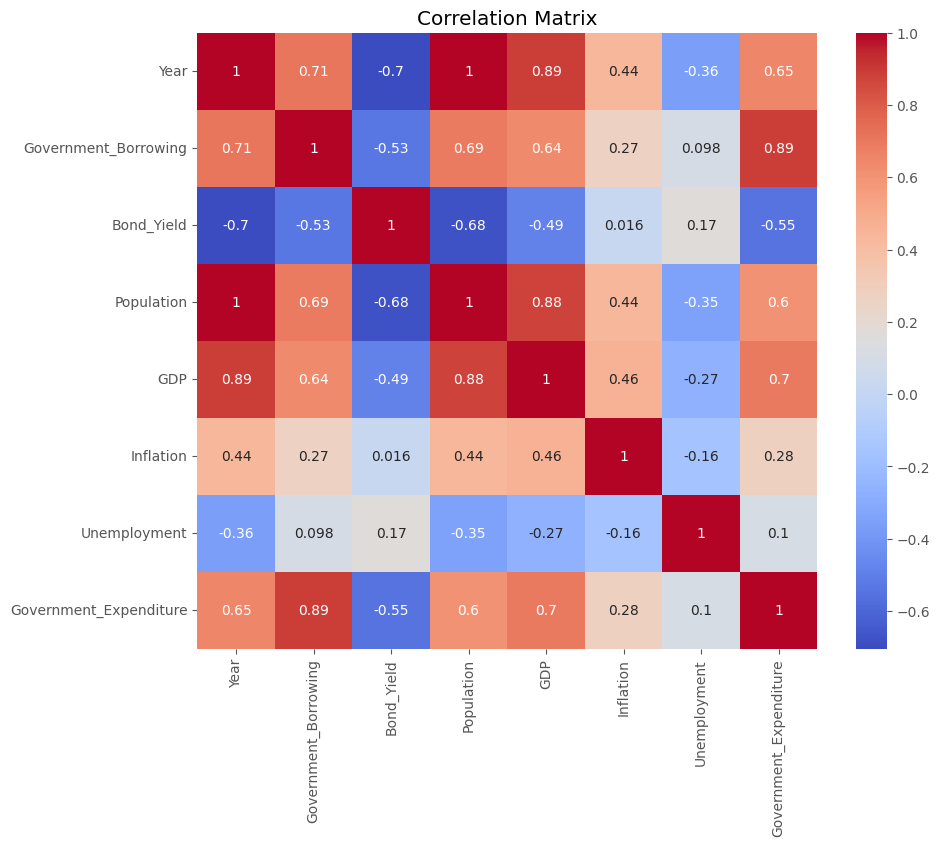

In [22]:
plt.figure(figsize=(10,8))

sns.heatmap(
    master.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

## **Government Borrowing Trend**

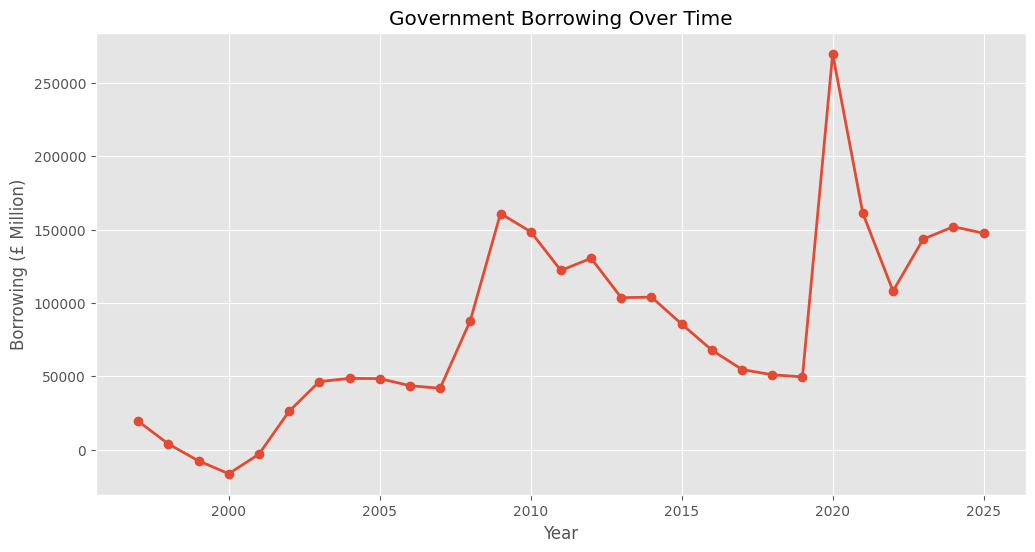

In [23]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["Government_Borrowing"],
    marker="o",
    linewidth=2
)

plt.title("Government Borrowing Over Time")

plt.xlabel("Year")

plt.ylabel("Borrowing (£ Million)")

plt.grid(True)

plt.show()

## **Bond Yield Trend**


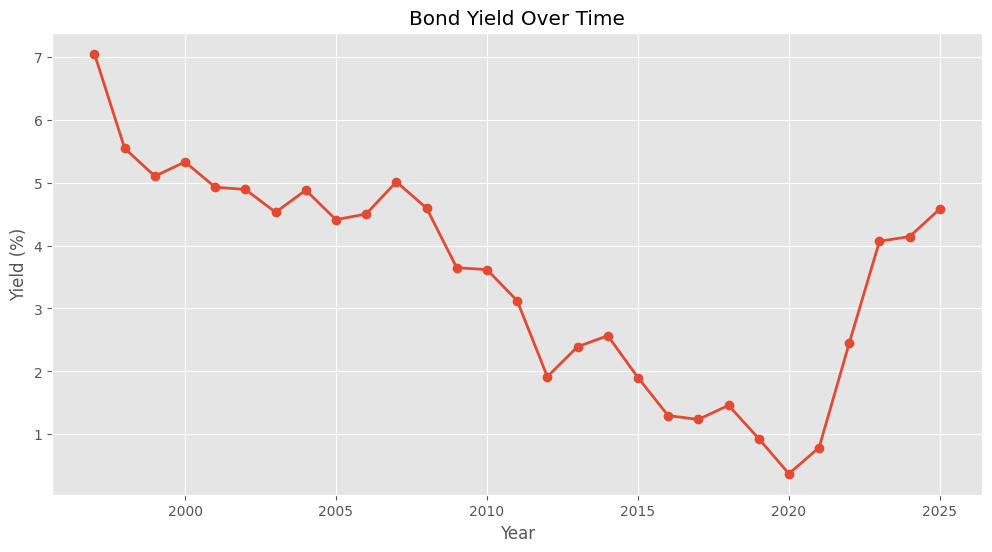

In [24]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["Bond_Yield"],
    marker="o",
    linewidth=2
)

plt.title("Bond Yield Over Time")

plt.xlabel("Year")

plt.ylabel("Yield (%)")

plt.grid(True)

plt.show()

## **GDP Trend**

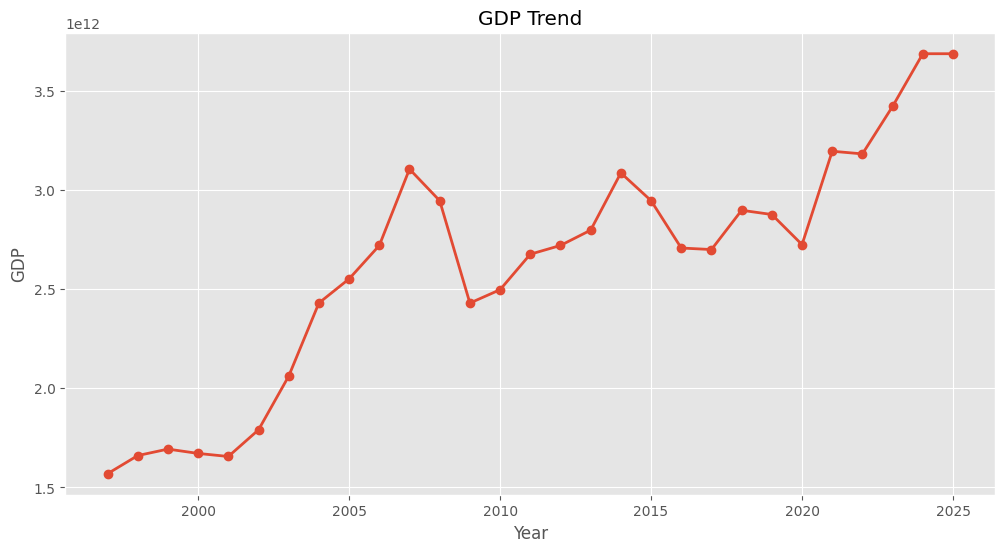

In [25]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["GDP"],
    marker="o",
    linewidth=2
)

plt.title("GDP Trend")

plt.xlabel("Year")

plt.ylabel("GDP")

plt.grid(True)

plt.show()

## **Inflation Trend**

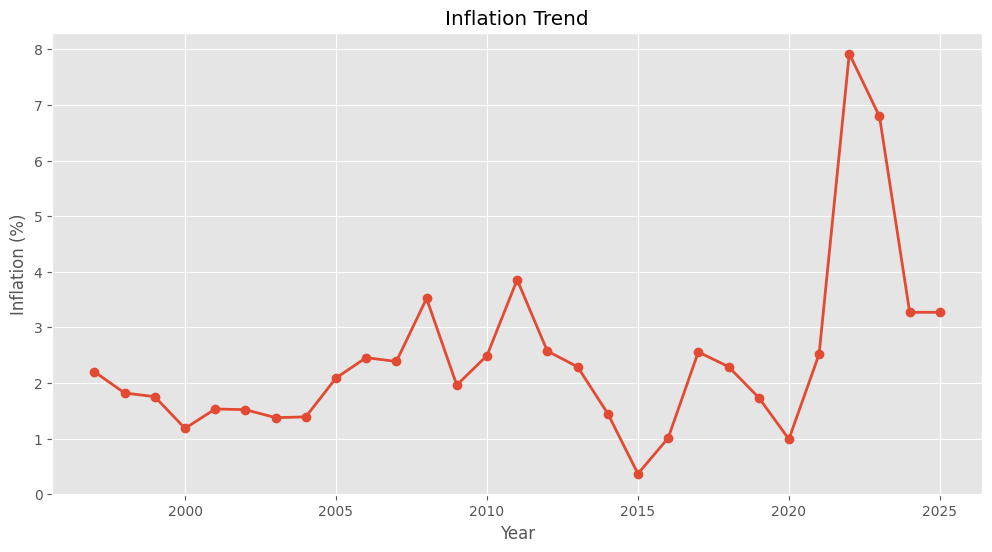

In [26]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["Inflation"],
    marker="o",
    linewidth=2
)

plt.title("Inflation Trend")

plt.xlabel("Year")

plt.ylabel("Inflation (%)")

plt.grid(True)

plt.show()

## **Unemployment Trend**

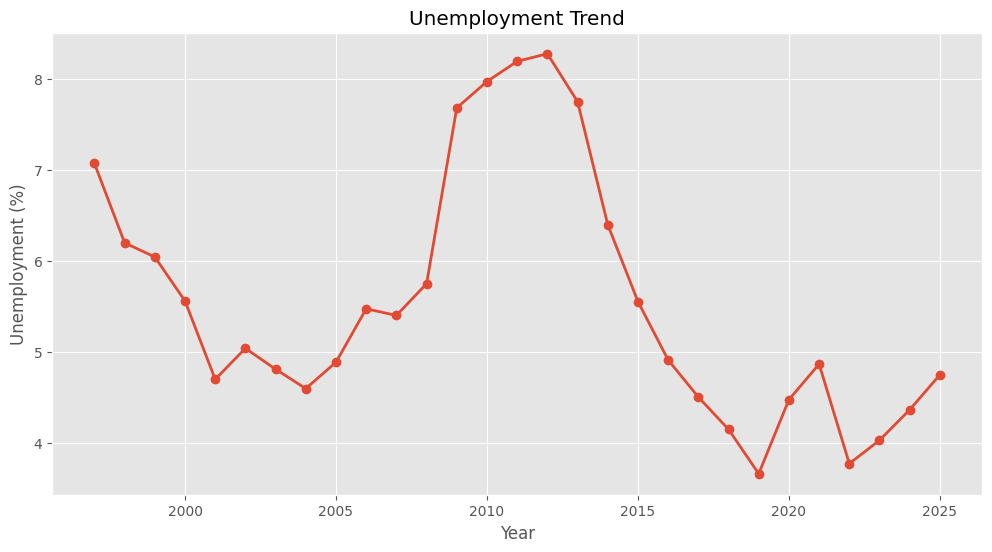

In [27]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["Unemployment"],
    marker="o",
    linewidth=2
)

plt.title("Unemployment Trend")

plt.xlabel("Year")

plt.ylabel("Unemployment (%)")

plt.grid(True)

plt.show()

## **Distribution of Variables**

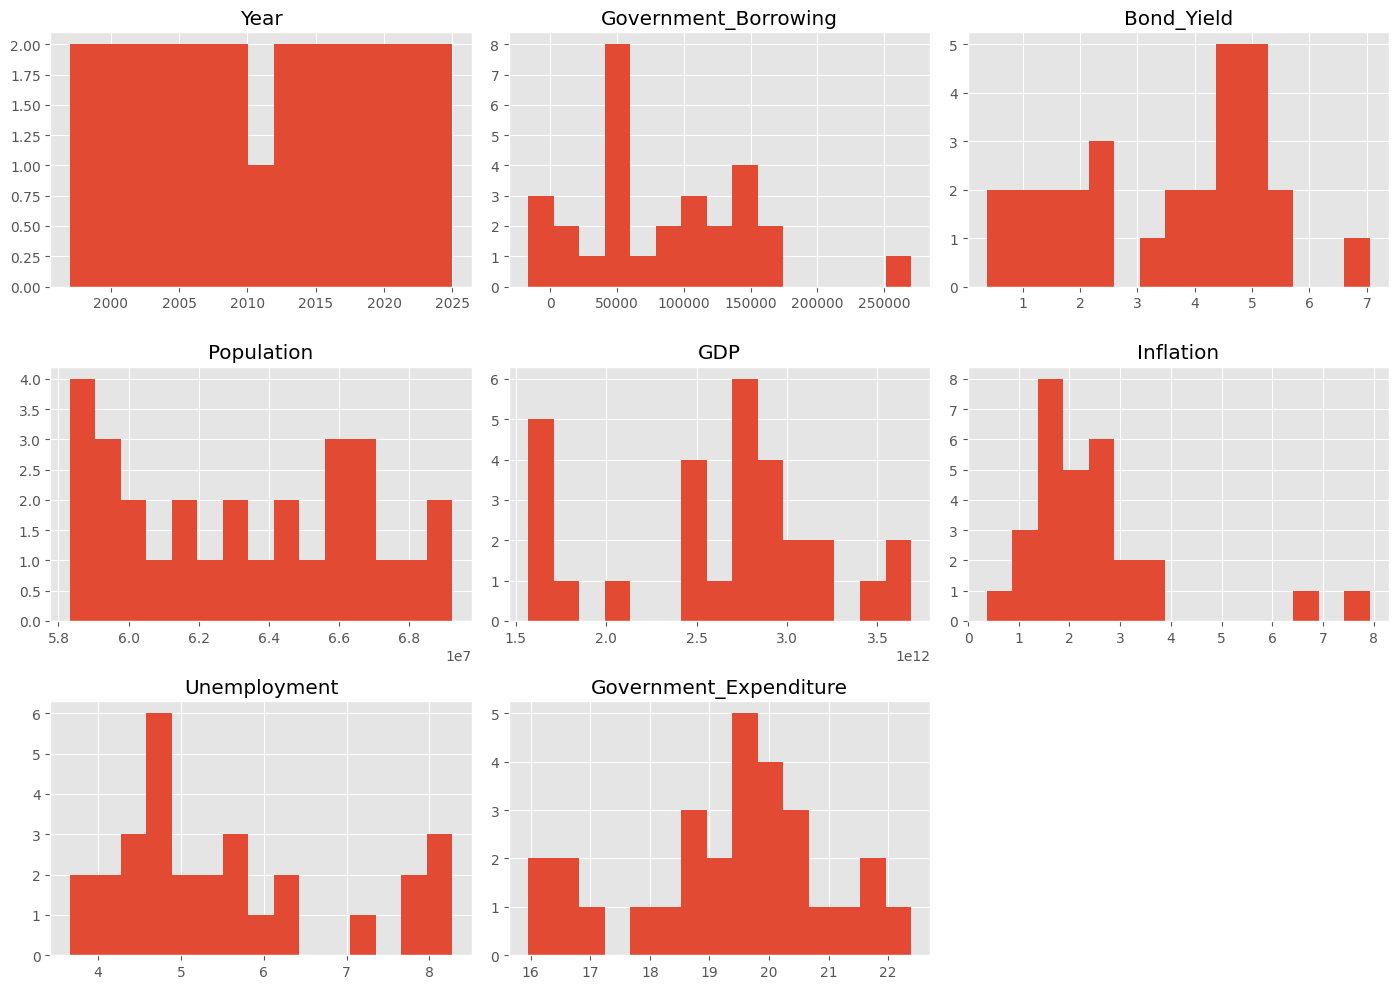

In [28]:
master.hist(
    figsize=(14,10),
    bins=15
)

plt.tight_layout()

plt.show()

## **Boxplots of Numerical Variables**

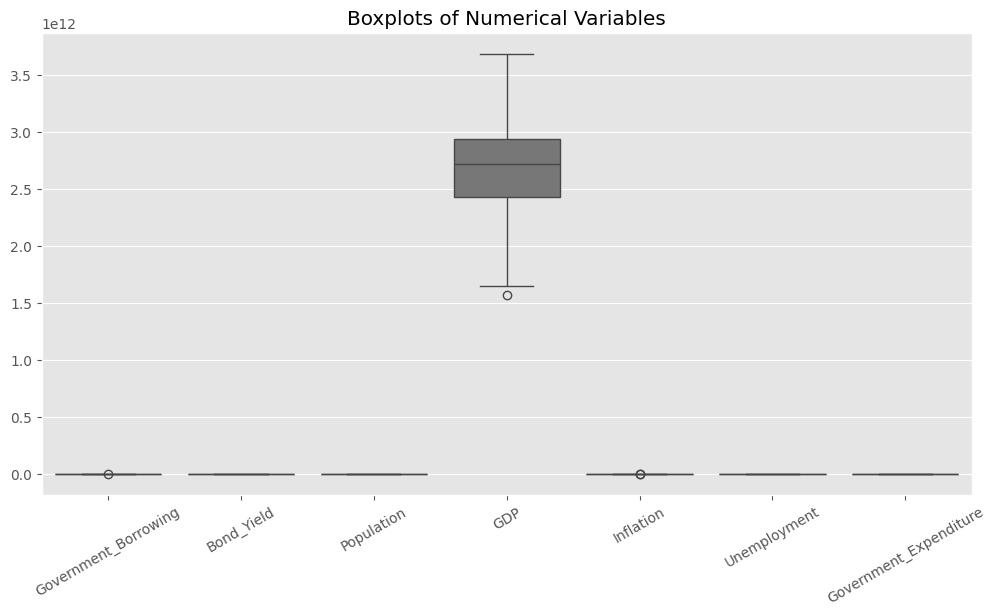

In [29]:
plt.figure(figsize=(12,6))

sns.boxplot(data=master.drop(columns=["Year"]))

plt.xticks(rotation=30)

plt.title("Boxplots of Numerical Variables")

plt.show()

# **Agent-Based Economic Simulation**

## **Simulation Parameters**

In [30]:

# REPRODUCIBILITY

BASE_SEED = 42

# INITIALISING RANDOM NUMBER GENERATORS
np.random.seed(BASE_SEED)
random.seed(BASE_SEED)


# NUMBER OF AGENTS

NUM_BANKS = 5
NUM_INVESTORS = 20
NUM_HOUSEHOLDS = 100


# HISTORICAL ECONOMIC DATA INTEGRATION

HISTORICAL_ECONOMIC_DATA = (
    economic_data.copy().reset_index(drop=True)
)

# VERIFYING HISTORICAL OBSERVATIONS
if HISTORICAL_ECONOMIC_DATA.empty:
    raise ValueError("Historical economic data is empty.")

if HISTORICAL_ECONOMIC_DATA["Year"].duplicated().any():
    raise ValueError("Duplicate historical years detected.")

# SETTING ONE SIMULATION STEP PER HISTORICAL YEAR
SIMULATION_STEPS = len(HISTORICAL_ECONOMIC_DATA)

# CONFIGURING TOTAL EVALUATION RUNS
MONTE_CARLO_RUNS = 30


# HISTORICAL REFERENCE VALUES

HISTORICAL_ANNUAL_BORROWING = float(
    HISTORICAL_ECONOMIC_DATA[
        "Government_Borrowing"
    ].iloc[-1]
)

INITIAL_BOND_YIELD = float(
    HISTORICAL_ECONOMIC_DATA[
        "Bond_Yield"
    ].iloc[-1]
)


# NORMALISING HISTORICAL GOVERNMENT BORROWING

# RETAINING POSITIVE NET BORROWING VALUES
borrowing_values = (
    HISTORICAL_ECONOMIC_DATA[
        "Government_Borrowing"
    ].clip(lower=0)
)

# CALCULATING THE MEDIAN POSITIVE BORROWING REFERENCE
positive_borrowing = borrowing_values[
    borrowing_values > 0
]

borrowing_reference = positive_borrowing.median()

if (
    pd.isna(borrowing_reference)
    or borrowing_reference <= 0
):
    raise ValueError(
        "A valid positive borrowing reference is required."
    )

# CALCULATING THE RELATIVE BORROWING INDEX
HISTORICAL_ECONOMIC_DATA["Borrowing_Index"] = (
    borrowing_values / borrowing_reference
)

# VERIFYING BORROWING INDEX VALUES
assert np.isfinite(
    HISTORICAL_ECONOMIC_DATA["Borrowing_Index"]
).all()

assert (
    HISTORICAL_ECONOMIC_DATA["Borrowing_Index"] >= 0
).all()


# GDP AND INFLATION STATE THRESHOLDS

GDP_LOW_THRESHOLD = (
    HISTORICAL_ECONOMIC_DATA["GDP"].quantile(0.33)
)

GDP_HIGH_THRESHOLD = (
    HISTORICAL_ECONOMIC_DATA["GDP"].quantile(0.66)
)

INFLATION_LOW_THRESHOLD = (
    HISTORICAL_ECONOMIC_DATA["Inflation"].quantile(0.33)
)

INFLATION_HIGH_THRESHOLD = (
    HISTORICAL_ECONOMIC_DATA["Inflation"].quantile(0.66)
)


# FINANCIAL SETTINGS (£)

BOND_PRICE = 100.0

INITIAL_BOND_LIABILITY = 0.0
INITIAL_GOVERNMENT_CASH = 0.0


# BANK SETTINGS

BANK_INITIAL_CAPITAL = 5_000_000.0
BANK_BOND_BUDGET = 20_000.0


# INSTITUTIONAL INVESTOR SETTINGS

INVESTOR_INITIAL_WEALTH = 100_000.0


# HOUSEHOLD SETTINGS

HOUSEHOLD_INITIAL_WEALTH = 50_000.0
HOUSEHOLD_INCOME = 3_000.0
HOUSEHOLD_CONSUMPTION_RATE = 0.70
HOUSEHOLD_SAVINGS_INVESTMENT_RATE = 0.10


# GOVERNMENT BOND SETTINGS

NEW_BONDS_PER_STEP = 100_000.0

BASE_BOND_ISSUANCE = NEW_BONDS_PER_STEP

INTEREST_PAYMENT_RATE = 0.03


# Q-LEARNING CONFIGURATION

RL_ALPHA = 0.10
RL_GAMMA = 0.95

RL_INITIAL_EPSILON = 1.0
RL_MIN_EPSILON = 0.05
RL_EPSILON_DECAY = 0.995

RL_TRAINING_EPISODES = 100


# AVAILABLE INVESTMENT ACTIONS

RL_ACTIONS = [
    0.00,
    0.05,
    0.10,
    0.15,
    0.20
]


# DISCRETE STATE THRESHOLDS

YIELD_LOW_THRESHOLD = 3.0
YIELD_HIGH_THRESHOLD = 5.0

CASH_LOW_THRESHOLD = 0.25
CASH_HIGH_THRESHOLD = 0.60

HOLDINGS_LOW_THRESHOLD = 0.25
HOLDINGS_HIGH_THRESHOLD = 0.75


# RISK-AVERSION EXPERIMENTAL SCENARIOS

RL_RISK_SCENARIOS = {
    "High Risk Aversion": 0.10,
    "Medium Risk Aversion": 0.05,
    "Low Risk Aversion": 0.01
}


# RANDOM SEEDS FOR REPEATED EVALUATION

EXPERIMENT_SEEDS = [
    1, 10, 42, 100, 500,
    1000, 2026, 2027, 2028, 2029
]


# VERIFYING EXPERIMENTAL CONFIGURATION

assert len(EXPERIMENT_SEEDS) == 10

assert (
    len(RL_RISK_SCENARIOS) * len(EXPERIMENT_SEEDS)
    == MONTE_CARLO_RUNS
)

assert SIMULATION_STEPS == len(HISTORICAL_ECONOMIC_DATA)

assert RL_ALPHA > 0 and RL_ALPHA <= 1
assert RL_GAMMA >= 0 and RL_GAMMA <= 1

assert 0 <= RL_MIN_EPSILON <= RL_INITIAL_EPSILON <= 1


# DISPLAYING SIMULATION CONFIGURATION

print("=" * 65)
print("SIMULATION CONFIGURATION")
print("=" * 65)

print("\nAGENT CONFIGURATION")
print("Banks:", NUM_BANKS)
print("Institutional investors:", NUM_INVESTORS)
print("Households:", NUM_HOUSEHOLDS)
print("Total financial agents:",
      NUM_BANKS + NUM_INVESTORS + NUM_HOUSEHOLDS)

print("\nHISTORICAL ECONOMIC DATA")
print("Observations:", SIMULATION_STEPS)
print(
    "Historical years:",
    HISTORICAL_ECONOMIC_DATA["Year"].min(),
    "-",
    HISTORICAL_ECONOMIC_DATA["Year"].max()
)

print("Latest government borrowing:",
      HISTORICAL_ANNUAL_BORROWING)

print("Initial bond yield (%):",
      INITIAL_BOND_YIELD)

print("Median positive borrowing reference:",
      borrowing_reference)

print(
    "Borrowing index range:",
    round(
        HISTORICAL_ECONOMIC_DATA["Borrowing_Index"].min(),
        3
    ),
    "-",
    round(
        HISTORICAL_ECONOMIC_DATA["Borrowing_Index"].max(),
        3
    )
)

print("\nQ-LEARNING CONFIGURATION")
print("Learning rate:", RL_ALPHA)
print("Discount factor:", RL_GAMMA)
print("Initial epsilon:", RL_INITIAL_EPSILON)
print("Minimum epsilon:", RL_MIN_EPSILON)
print("Epsilon decay:", RL_EPSILON_DECAY)
print("Training episodes:", RL_TRAINING_EPISODES)
print("Available actions:", RL_ACTIONS)

print("\nRISK-AVERSION SCENARIOS")

for scenario, coefficient in RL_RISK_SCENARIOS.items():
    print(f"{scenario}: {coefficient}")

print("\nEXPERIMENTAL DESIGN")
print("Evaluation seeds:", len(EXPERIMENT_SEEDS))
print("Total evaluation runs:", MONTE_CARLO_RUNS)

print("\nFINANCIAL SETTINGS")
print("Bond price (£):", BOND_PRICE)
print("Baseline bond issuance (£):", BASE_BOND_ISSUANCE)
print("Interest payment rate:", INTEREST_PAYMENT_RATE)

print("\nConfiguration verification: PASSED")

SIMULATION CONFIGURATION

AGENT CONFIGURATION
Banks: 5
Institutional investors: 20
Households: 100
Total financial agents: 125

HISTORICAL ECONOMIC DATA
Observations: 29
Historical years: 1997 - 2025
Latest government borrowing: 147593.0
Initial bond yield (%): 4.5833
Median positive borrowing reference: 86811.0
Borrowing index range: 0.0 - 3.11

Q-LEARNING CONFIGURATION
Learning rate: 0.1
Discount factor: 0.95
Initial epsilon: 1.0
Minimum epsilon: 0.05
Epsilon decay: 0.995
Training episodes: 100
Available actions: [0.0, 0.05, 0.1, 0.15, 0.2]

RISK-AVERSION SCENARIOS
High Risk Aversion: 0.1
Medium Risk Aversion: 0.05
Low Risk Aversion: 0.01

EXPERIMENTAL DESIGN
Evaluation seeds: 10
Total evaluation runs: 30

FINANCIAL SETTINGS
Bond price (£): 100.0
Baseline bond issuance (£): 100000.0
Interest payment rate: 0.03

Configuration verification: PASSED


### **Experimental Design**

In [31]:
# 1. Agent population
print("=" * 65)
print("EXPERIMENTAL DESIGN: HYBRID RL-BASED UK DEBT ABM")
print("=" * 65)

print("\n1. AGENT CONFIGURATION")
print("-" * 65)
print(f"Number of banks:              {NUM_BANKS}")
print(f"Number of institutional investors: {NUM_INVESTORS}")
print(f"Number of households:          {NUM_HOUSEHOLDS}")
print(f"Total simulation agents:       {NUM_BANKS + NUM_INVESTORS + NUM_HOUSEHOLDS + 1}")
print("Government agent:              1")

# 2. Simulation configuration
print("\n2. SIMULATION CONFIGURATION")
print("-" * 65)
print(f"Simulation steps per episode: {SIMULATION_STEPS}")
print(f"RL training episodes:          {RL_TRAINING_EPISODES}")
print(f"Evaluation seeds per scenario: {len(EXPERIMENT_SEEDS)}")
print(f"Base random seed:              {BASE_SEED}")

# 3. Q-learning configuration
print("\n3. Q-LEARNING CONFIGURATION")
print("-" * 65)
print(f"Learning rate (alpha):         {RL_ALPHA}")
print(f"Discount factor (gamma):       {RL_GAMMA}")
print(f"Initial exploration rate:      {RL_INITIAL_EPSILON}")
print(f"Minimum exploration rate:      {RL_MIN_EPSILON}")
print(f"Epsilon decay rate:            {RL_EPSILON_DECAY}")
print(f"Investor actions:              {RL_ACTIONS}")
print(f"Number of available actions:   {len(RL_ACTIONS)}")

# 4. State representation
print("\n4. RL STATE REPRESENTATION")
print("-" * 65)
print("State variables:")
print("  - Government bond yield level")
print("  - Investor cash position")
print("  - Investor bond holdings")

print("\nYield categories:")
print(f"  Low:    Yield < {YIELD_LOW_THRESHOLD}%")
print(f"  Medium: {YIELD_LOW_THRESHOLD}% to {YIELD_HIGH_THRESHOLD}%")
print(f"  High:   Yield >= {YIELD_HIGH_THRESHOLD}%")

print("\nCash and holdings categories:")
print(f"  Low threshold:  {CASH_LOW_THRESHOLD} / {HOLDINGS_LOW_THRESHOLD}")
print(f"  High threshold: {CASH_HIGH_THRESHOLD} / {HOLDINGS_HIGH_THRESHOLD}")

# 5. Risk-aversion scenarios
print("\n5. RL RISK-AVERSION SCENARIOS")
print("-" * 65)

for scenario_name, risk_aversion in RL_RISK_SCENARIOS.items():
    print(f"{scenario_name}: risk-aversion penalty = {risk_aversion}")

# 6. Experiment design
training_runs = len(RL_RISK_SCENARIOS) * RL_TRAINING_EPISODES
evaluation_runs = len(RL_RISK_SCENARIOS) * len(EXPERIMENT_SEEDS)

print("\n6. EXPERIMENTAL RUNS")
print("-" * 65)
print(f"Number of risk scenarios:      {len(RL_RISK_SCENARIOS)}")
print(f"Training episodes per scenario: {RL_TRAINING_EPISODES}")
print(f"Total training episodes:       {training_runs}")
print(f"Evaluation seeds per scenario: {len(EXPERIMENT_SEEDS)}")
print(f"Total evaluation runs:         {evaluation_runs}")

EXPERIMENTAL DESIGN: HYBRID RL-BASED UK DEBT ABM

1. AGENT CONFIGURATION
-----------------------------------------------------------------
Number of banks:              5
Number of institutional investors: 20
Number of households:          100
Total simulation agents:       126
Government agent:              1

2. SIMULATION CONFIGURATION
-----------------------------------------------------------------
Simulation steps per episode: 29
RL training episodes:          100
Evaluation seeds per scenario: 10
Base random seed:              42

3. Q-LEARNING CONFIGURATION
-----------------------------------------------------------------
Learning rate (alpha):         0.1
Discount factor (gamma):       0.95
Initial exploration rate:      1.0
Minimum exploration rate:      0.05
Epsilon decay rate:            0.995
Investor actions:              [0.0, 0.05, 0.1, 0.15, 0.2]
Number of available actions:   5

4. RL STATE REPRESENTATION
---------------------------------------------------------------

## **Government Agent**

In [32]:
class GovernmentAgent:

    def __init__(self):

        # Government financial position
        self.debt = INITIAL_BOND_LIABILITY
        self.cash = INITIAL_GOVERNMENT_CASH
        self.bond_yield = INITIAL_BOND_YIELD

        self.total_bonds = 0.0
        self.available_bonds = 0.0

        # Historical economic conditions
        self.current_year = None
        self.historical_borrowing = 0.0
        self.borrowing_index = 1.0
        self.historical_yield = INITIAL_BOND_YIELD

        self.gdp = 0.0
        self.inflation = 0.0
        self.unemployment = 0.0
        self.government_expenditure = 0.0

        # Current-period coupon accounting variables
        self.interest_due = 0.0
        self.interest_paid = 0.0
        self.interest_unpaid = 0.0
        self.interest_capitalised = 0.0

        # Cumulative coupon accounting variables
        self.cumulative_interest_due = 0.0
        self.cumulative_interest_paid = 0.0
        self.cumulative_interest_unpaid = 0.0
        self.cumulative_interest_capitalised = 0.0

    # UPDATE HISTORICAL ECONOMIC CONDITIONS

    def set_economic_conditions(self, economic_row):

        self.current_year = int(economic_row["Year"])

        self.historical_borrowing = float(
            economic_row["Government_Borrowing"]
        )

        self.borrowing_index = float(
            economic_row["Borrowing_Index"]
        )

        self.historical_yield = float(
            economic_row["Bond_Yield"]
        )

        self.gdp = float(
            economic_row["GDP"]
        )

        self.inflation = float(
            economic_row["Inflation"]
        )

        self.unemployment = float(
            economic_row["Unemployment"]
        )

        self.government_expenditure = float(
            economic_row["Government_Expenditure"]
        )

    # GOVERNMENT BOND ISSUANCE

    def issue_bonds(self):
        """
        Issues government bonds according to the historical
        government borrowing index.
        """

        self.available_bonds = (
            BASE_BOND_ISSUANCE * self.borrowing_index
        )

    # SELL GOVERNMENT BONDS

    def sell_bonds(self, buyer, desired_amount):
        """Sells bonds at par and records both sides of the transaction."""

        requested = max(0.0, float(desired_amount))

        affordable = min(requested, buyer.cash)

        amount_sold = min(
            affordable,
            self.available_bonds
        )

        if amount_sold <= 0:
            return 0.0

        # Updates the buyer's financial position
        buyer.cash -= amount_sold

        buyer.bonds_owned += amount_sold / BOND_PRICE

        # Updates government financial accounts
        self.cash += amount_sold

        self.debt += amount_sold

        self.total_bonds += amount_sold

        self.available_bonds -= amount_sold

        # Records the buyer's investment
        buyer.last_investment = amount_sold

        buyer.last_action = "Buy Bonds"

        return amount_sold

    # GOVERNMENT COUPON PAYMENTS

    def pay_coupons(self, holders):
        """Pays coupons proportionally to actual government bondholders."""

        # Calculates the coupon obligation for every bondholder
        self.interest_due = sum(
            holder.bond_value * INTEREST_PAYMENT_RATE
            for holder in holders
        )

        # Resets current-period coupon payments
        self.interest_paid = 0.0

        for holder in holders:
            holder.interest_income = 0.0

        # Determines the proportion of coupon obligations that can be paid
        if self.interest_due > 0:

            payment_ratio = min(
                1.0,
                self.cash / self.interest_due
            )

        else:

            payment_ratio = 0.0

        # Allocates coupon payments to actual bondholders
        for holder in holders:

            due = (
                holder.bond_value
                * INTEREST_PAYMENT_RATE
            )

            payment = due * payment_ratio

            # Transfers coupon income to the bondholder
            holder.cash += payment

            holder.interest_income = payment

            # Records cumulative coupon income for each agent
            holder.cumulative_interest_income += payment

            self.interest_paid += payment

        # Updates government cash after coupon payments
        self.cash -= self.interest_paid

        # Calculates unpaid coupon obligations
        self.interest_unpaid = max(
            0.0,
            self.interest_due - self.interest_paid
        )

        # Capitalises unpaid interest into government debt
        self.interest_capitalised = self.interest_unpaid

        self.debt += self.interest_capitalised

        # Updates cumulative coupon accounting
        self.cumulative_interest_due += self.interest_due

        self.cumulative_interest_paid += self.interest_paid

        self.cumulative_interest_unpaid += self.interest_unpaid

        self.cumulative_interest_capitalised += (
            self.interest_capitalised
        )

    # UPDATE GOVERNMENT BOND YIELD

    def update_bond_yield(self):
        """
        Updates the government bond yield using the historical
        bond yield for the current simulation year.

        Random yield shocks are no longer applied.
        """

        self.bond_yield = max(
            0.0,
            self.historical_yield
        )

In [33]:

class FinancialAgent:

    def __init__(
        self,
        initial_cash,
        risk_aversion=0.05,
        q_table=None,
        epsilon=RL_INITIAL_EPSILON,
        learning_enabled=True,
        actions=None
    ):

        # INITIALISING FINANCIAL ASSETS
        self.cash = float(initial_cash)
        self.bonds_owned = 0.0

        # TRACKING INTEREST INCOME
        self.interest_income = 0.0
        self.cumulative_interest_income = 0.0

        # INITIALISING INVESTMENT DECISION RECORDS
        self.last_action = "Hold"
        self.last_investment = 0.0

        # CONFIGURING REINFORCEMENT LEARNING
        self.risk_aversion = risk_aversion
        self.q_table = q_table if q_table is not None else {}
        self.epsilon = epsilon
        self.learning_enabled = learning_enabled

        # SETTING AVAILABLE INVESTMENT ACTIONS
        self.actions = (
            actions if actions is not None else RL_ACTIONS
        )

        # INITIALISING MACROECONOMIC VARIABLES
        self.gdp = 0.0
        self.inflation = 0.0

        # INITIALISING LEARNING RECORDS
        self.previous_state = None
        self.previous_action = None
        self.previous_wealth = 0.0

        self.total_reward = 0.0
        self.learning_steps = 0
        self.selected_action_fraction = 0.0

    # CALCULATING THE VALUE OF GOVERNMENT BONDS
    @property
    def bond_value(self):
        return self.bonds_owned * BOND_PRICE

    # CALCULATING TOTAL FINANCIAL WEALTH
    @property
    def wealth(self):
        return self.cash + self.bond_value

    # RETURNING TOTAL FINANCIAL ASSETS
    @property
    def total_assets(self):
        return self.wealth

    # CLASSIFYING THE CURRENT ECONOMIC STATE
    def get_state(self, government):

        total_wealth = max(self.wealth, 1e-9)

        cash_ratio = self.cash / total_wealth
        holdings_ratio = self.bond_value / total_wealth

        # CLASSIFYING GOVERNMENT BOND YIELD
        if government.bond_yield < YIELD_LOW_THRESHOLD:
            yield_state = 0
        elif government.bond_yield < YIELD_HIGH_THRESHOLD:
            yield_state = 1
        else:
            yield_state = 2

        # CLASSIFYING CASH RATIO
        if cash_ratio < CASH_LOW_THRESHOLD:
            cash_state = 0
        elif cash_ratio < CASH_HIGH_THRESHOLD:
            cash_state = 1
        else:
            cash_state = 2

        # CLASSIFYING BOND HOLDING RATIO
        if holdings_ratio < HOLDINGS_LOW_THRESHOLD:
            holdings_state = 0
        elif holdings_ratio < HOLDINGS_HIGH_THRESHOLD:
            holdings_state = 1
        else:
            holdings_state = 2

        # CLASSIFYING GDP
        if self.gdp < GDP_LOW_THRESHOLD:
            gdp_state = 0
        elif self.gdp < GDP_HIGH_THRESHOLD:
            gdp_state = 1
        else:
            gdp_state = 2

        # CLASSIFYING INFLATION
        if self.inflation < INFLATION_LOW_THRESHOLD:
            inflation_state = 0
        elif self.inflation < INFLATION_HIGH_THRESHOLD:
            inflation_state = 1
        else:
            inflation_state = 2

        return (
            yield_state,
            cash_state,
            holdings_state,
            gdp_state,
            inflation_state
        )

    # RETRIEVING Q-VALUES WITHOUT MODIFYING EVALUATION TABLES
    def get_q_values(self, state):

        if state not in self.q_table:

            # RETURNING TEMPORARY ZERO VALUES DURING EVALUATION
            if not self.learning_enabled:
                return np.zeros(
                    len(self.actions),
                    dtype=float
                )

            # INITIALISING NEW STATES DURING TRAINING
            self.q_table[state] = np.zeros(
                len(self.actions),
                dtype=float
            )

        return self.q_table[state]

    # SELECTING AN INVESTMENT ACTION USING EPSILON-GREEDY POLICY
    def choose_action(self, state):

        # EXPLORING AVAILABLE ACTIONS DURING TRAINING
        if (
            self.learning_enabled
            and np.random.random() < self.epsilon
        ):
            return int(
                np.random.randint(len(self.actions))
            )

        # RETRIEVING THE CURRENT STATE ACTION VALUES
        q_values = self.get_q_values(state)

        # IDENTIFYING ACTIONS WITH THE HIGHEST Q-VALUE
        best_actions = np.flatnonzero(
            np.isclose(q_values, q_values.max())
        )

        # SELECTING AMONG EQUALLY VALUED ACTIONS
        return int(
            np.random.choice(best_actions)
        )

    # STARTING A NEW INVESTMENT DECISION
    def start_decision(self, government):

        # RECORDING PREVIOUS FINANCIAL WEALTH
        self.previous_wealth = self.wealth

        # OBSERVING THE CURRENT ECONOMIC STATE
        self.previous_state = self.get_state(
            government
        )

        # SELECTING AN INVESTMENT ACTION
        self.previous_action = self.choose_action(
            self.previous_state
        )

        return self.actions[self.previous_action]

    # UPDATING THE Q-LEARNING POLICY
    def update_learning(
        self,
        government,
        yield_change,
        done=False,
        additional_reward=0.0
    ):

        # SKIPPING LEARNING DURING POLICY EVALUATION
        if (
            not self.learning_enabled
            or self.previous_state is None
            or self.previous_action is None
        ):
            return

        # OBSERVING THE NEXT ECONOMIC STATE
        next_state = self.get_state(
            government
        )

        # CALCULATING THE CHANGE IN FINANCIAL WEALTH
        wealth_change = (
            self.wealth - self.previous_wealth
        )

        # CALCULATING THE FINANCIAL RISK PENALTY
        risk_penalty = (
            self.risk_aversion
            * self.bond_value
            * abs(yield_change) / 100.0
        )

        # CALCULATING THE TOTAL LEARNING REWARD
        reward = (
            wealth_change
            - risk_penalty
            + additional_reward
        )

        # RETRIEVING CURRENT STATE ACTION VALUES
        current_q_values = self.get_q_values(
            self.previous_state
        )

        old_q_value = current_q_values[
            self.previous_action
        ]

        # CALCULATING THE FUTURE STATE VALUE
        if done:
            future_q_value = 0.0
        else:
            future_q_value = np.max(
                self.get_q_values(next_state)
            )

        # APPLYING THE Q-LEARNING UPDATE RULE
        updated_q_value = old_q_value + RL_ALPHA * (
            reward
            + RL_GAMMA * future_q_value
            - old_q_value
        )

        # UPDATING THE SELECTED ACTION VALUE
        current_q_values[
            self.previous_action
        ] = updated_q_value

        # RECORDING LEARNING PERFORMANCE
        self.total_reward += reward
        self.learning_steps += 1

    # RESETTING EPISODE LEARNING RECORDS
    def reset_episode_records(self):

        self.previous_state = None
        self.previous_action = None
        self.previous_wealth = 0.0

        self.total_reward = 0.0
        self.learning_steps = 0
        self.selected_action_fraction = 0.0

    # DECAYING THE EXPLORATION RATE
    def decay_epsilon(self):

        self.epsilon = max(
            RL_MIN_EPSILON,
            self.epsilon * RL_EPSILON_DECAY
        )

In [34]:

# VERIFYING Q-TABLE IMMUTABILITY DURING EVALUATION

test_q_table = {
    (0, 1, 2, 0, 1): np.array(
        [0.5, 1.0, 1.5, 2.0, 2.5],
        dtype=float
    )
}

# CREATING AN EVALUATION AGENT
evaluation_agent = FinancialAgent(
    initial_cash=100000,
    q_table=test_q_table,
    epsilon=0.0,
    learning_enabled=False
)

# RECORDING THE ORIGINAL Q-TABLE
original_q_table = {
    state: values.copy()
    for state, values in evaluation_agent.q_table.items()
}

original_state_count = len(
    evaluation_agent.q_table
)

# TESTING AN UNSEEN STATE
unseen_state = (2, 2, 2, 2, 2)

q_values = evaluation_agent.get_q_values(
    unseen_state
)

# VERIFYING THAT NO NEW STATE IS CREATED
assert unseen_state not in evaluation_agent.q_table

assert len(
    evaluation_agent.q_table
) == original_state_count

# VERIFYING THAT EXISTING Q-VALUES REMAIN UNCHANGED
for state in original_q_table:

    assert np.array_equal(
        evaluation_agent.q_table[state],
        original_q_table[state]
    )

# VERIFYING TEMPORARY ZERO VALUES
assert np.array_equal(
    q_values,
    np.zeros(len(RL_ACTIONS))
)

print("=" * 55)
print("Q-TABLE IMMUTABILITY TEST")
print("=" * 55)
print("Original Q-table states:", original_state_count)
print("Evaluation Q-table states:",
      len(evaluation_agent.q_table))

Q-TABLE IMMUTABILITY TEST
Original Q-table states: 1
Evaluation Q-table states: 1


## **Bank Agent**

In [35]:
class BankAgent(FinancialAgent):

    def __init__(
        self,
        bank_id,
        risk_aversion=0.05,
        q_table=None,
        epsilon=RL_INITIAL_EPSILON,
        learning_enabled=True
    ):

        # INITIALISING THE FINANCIAL AGENT
        super().__init__(
            initial_cash=BANK_INITIAL_CAPITAL,
            risk_aversion=risk_aversion,
            q_table=q_table,
            epsilon=epsilon,
            learning_enabled=learning_enabled,
            actions=RL_ACTIONS
        )

        self.bank_id = bank_id

    def decide_investment(self, government):

        # RESETTING THE CURRENT INVESTMENT RECORD
        self.last_investment = 0.0
        self.last_action = "Hold"

        # SELECTING THE Q-LEARNING INVESTMENT ACTION
        investment_fraction = self.start_decision(
            government
        )

        self.selected_action_fraction = investment_fraction

        # CALCULATING INVESTMENT FROM AVAILABLE BANK CASH
        desired_investment = (
            self.cash * investment_fraction
        )

        # APPLYING THE BANK INVESTMENT BUDGET
        return max(
            0.0,
            min(
                desired_investment,
                self.cash,
                BANK_BOND_BUDGET
            )
        )

    def update_learning(
        self,
        government,
        yield_change,
        done=False
    ):

        # UPDATING THE BANK Q-LEARNING POLICY
        super().update_learning(
            government,
            yield_change,
            done
        )

    def step(self, government):

        # EXECUTING THE BANK INVESTMENT DECISION
        desired = self.decide_investment(
            government
        )

        # EXECUTING THE GOVERNMENT BOND PURCHASE
        government.sell_bonds(
            self,
            desired
        )

        return desired

In [36]:
# INITIALISING THE GOVERNMENT AND BANK
government_test = GovernmentAgent()
bank_test = BankAgent(
    bank_id=1,
    risk_aversion=0.05,
    epsilon=0.0,
    learning_enabled=True
)

# SETTING AVAILABLE GOVERNMENT BONDS
government_test.available_bonds = 100_000.0

# RECORDING INITIAL FINANCIAL POSITIONS
initial_cash = bank_test.cash
initial_assets = bank_test.total_assets
initial_government_cash = government_test.cash
initial_government_debt = government_test.debt

# FORCING THE BANK TO SELECT THE 20% INVESTMENT ACTION
state = bank_test.get_state(government_test)

bank_test.q_table[state] = np.array(
    [0.0, 0.0, 0.0, 0.0, 1.0]
)

# EXECUTING THE BANK DECISION
actual_investment = bank_test.step(government_test)

# DISPLAYING THE RESULTS
print("BANK AGENT TRANSACTION TEST")
print("=" * 50)

print(f"Bank cash before: £{initial_cash:,.2f}")
print(f"Bank cash after: £{bank_test.cash:,.2f}")
print(f"Bond value: £{bank_test.bond_value:,.2f}")
print(f"Total assets before: £{initial_assets:,.2f}")
print(f"Total assets after: £{bank_test.total_assets:,.2f}")
print(f"Selected action fraction: {bank_test.selected_action_fraction}")
print(f"Amount invested: £{actual_investment:,.2f}")
print(f"Government cash: £{government_test.cash:,.2f}")
print(f"Government debt: £{government_test.debt:,.2f}")

# VERIFYING THE TRANSACTION
assert actual_investment > 0
assert np.isclose(bank_test.last_investment, actual_investment)

# VERIFYING BANK ASSET CONSERVATION
assert np.isclose(
    bank_test.total_assets,
    initial_assets
)

# VERIFYING GOVERNMENT ACCOUNTING
assert np.isclose(
    government_test.cash,
    initial_government_cash + actual_investment
)

assert np.isclose(
    government_test.debt,
    initial_government_debt + actual_investment
)

# VERIFYING BOND OWNERSHIP
assert np.isclose(
    bank_test.bond_value,
    actual_investment
)

assert np.isclose(
    government_test.total_bonds,
    actual_investment
)

assert np.isclose(
    government_test.available_bonds,
    100_000.0 - actual_investment
)

print("\nBank agent transaction test: PASSED")

BANK AGENT TRANSACTION TEST
Bank cash before: £5,000,000.00
Bank cash after: £4,980,000.00
Bond value: £20,000.00
Total assets before: £5,000,000.00
Total assets after: £5,000,000.00
Selected action fraction: 0.2
Amount invested: £20,000.00
Government cash: £20,000.00
Government debt: £20,000.00

Bank agent transaction test: PASSED


## **Q-Learning Investor Agent**

In [37]:
np.random.seed(BASE_SEED)
random.seed(BASE_SEED)

government_test = GovernmentAgent()

bank_test = BankAgent(
    bank_id=1,
    risk_aversion=0.05,
    epsilon=1.0,
    learning_enabled=True
)

government_test.available_bonds = 100_000.0

initial_wealth = bank_test.wealth

desired_investment = bank_test.decide_investment(
    government_test
)

actual_investment = government_test.sell_bonds(
    bank_test,
    desired_investment
)

government_test.pay_coupons([bank_test])

bank_test.update_learning(
    government_test,
    yield_change=0.0,
    done=False
)

print("BANK Q-LEARNING TEST")
print("=" * 45)

print("Bank ID:", bank_test.bank_id)
print("Initial wealth:", initial_wealth)
print("Selected investment fraction:",
      bank_test.selected_action_fraction)
print("Desired investment:", desired_investment)
print("Actual investment:", actual_investment)
print("Final cash:", bank_test.cash)
print("Bond value:", bank_test.bond_value)
print("Final wealth:", bank_test.wealth)
print("Total reward:", bank_test.total_reward)
print("Learning steps:", bank_test.learning_steps)
print("Q-table states:", len(bank_test.q_table))

assert actual_investment >= 0
assert actual_investment <= BANK_BOND_BUDGET
assert bank_test.cash >= -1e-6
assert bank_test.learning_steps == 1
assert len(bank_test.q_table) > 0

print("\nBank Q-learning test: PASSED")

BANK Q-LEARNING TEST
Bank ID: 1
Initial wealth: 5000000.0
Selected investment fraction: 0.2
Desired investment: 20000.0
Actual investment: 20000.0
Final cash: 4980600.0
Bond value: 20000.0
Final wealth: 5000600.0
Total reward: 600.0
Learning steps: 1
Q-table states: 1

Bank Q-learning test: PASSED


In [38]:
class InvestorAgent(FinancialAgent):

    def __init__(
        self,
        investor_id,
        risk_aversion=0.05,
        q_table=None,
        epsilon=RL_INITIAL_EPSILON,
        learning_enabled=True
    ):

        super().__init__(
            initial_cash=INVESTOR_INITIAL_WEALTH,
            risk_aversion=risk_aversion,
            q_table=q_table,
            epsilon=epsilon,
            learning_enabled=learning_enabled,
            actions=RL_ACTIONS
        )

        self.investor_id = investor_id

    def decide_investment(self, government):

        self.last_investment = 0.0
        self.last_action = "Hold"

        investment_fraction = self.start_decision(
            government
        )

        self.selected_action_fraction = investment_fraction

        desired_investment = (
            self.cash * investment_fraction
        )

        return max(
            0.0,
            min(desired_investment, self.cash)
        )

## **Household Agent**

In [39]:
np.random.seed(BASE_SEED)
random.seed(BASE_SEED)

government_test = GovernmentAgent()

investor_test = InvestorAgent(
    investor_id=1,
    risk_aversion=0.05,
    epsilon=1.0,
    learning_enabled=True
)

government_test.available_bonds = NEW_BONDS_PER_STEP

initial_wealth = investor_test.wealth

desired_investment = investor_test.decide_investment(
    government_test
)

actual_investment = government_test.sell_bonds(
    investor_test,
    desired_investment
)

government_test.pay_coupons([investor_test])

investor_test.update_learning(
    government_test,
    yield_change=0.0,
    done=False
)

print("INVESTOR Q-LEARNING TEST")
print("=" * 45)

print("Investor ID:", investor_test.investor_id)
print("Initial wealth:", initial_wealth)
print("Selected action fraction:",
      investor_test.selected_action_fraction)
print("Actual investment:", actual_investment)
print("Final wealth:", investor_test.wealth)
print("Total reward:", investor_test.total_reward)
print("Learning steps:", investor_test.learning_steps)
print("Q-table states:", len(investor_test.q_table))

assert investor_test.cash >= -1e-6
assert investor_test.bonds_owned >= 0
assert investor_test.learning_steps == 1
assert len(investor_test.q_table) > 0

print("\nInvestor Q-learning test: PASSED")

INVESTOR Q-LEARNING TEST
Investor ID: 1
Initial wealth: 100000.0
Selected action fraction: 0.2
Actual investment: 20000.0
Final wealth: 100600.0
Total reward: 600.0
Learning steps: 1
Q-table states: 1

Investor Q-learning test: PASSED


In [40]:

HOUSEHOLD_RL_ACTIONS = [
    (0.50, 0.00),
    (0.50, 0.10),
    (0.60, 0.10),
    (0.70, 0.10),
    (0.70, 0.20),
    (0.80, 0.00),
    (0.80, 0.10),
    (0.90, 0.00)
]


class HouseholdAgent(FinancialAgent):

    def __init__(
        self,
        household_id,
        risk_aversion=0.05,
        q_table=None,
        epsilon=RL_INITIAL_EPSILON,
        learning_enabled=True
    ):

        # INITIALISING THE FINANCIAL AGENT
        super().__init__(
            initial_cash=HOUSEHOLD_INITIAL_WEALTH,
            risk_aversion=risk_aversion,
            q_table=q_table,
            epsilon=epsilon,
            learning_enabled=learning_enabled,
            actions=HOUSEHOLD_RL_ACTIONS
        )

        self.household_id = household_id

        self.income = HOUSEHOLD_INCOME
        self.savings = 0.0
        self.consumption = 0.0

        self.selected_consumption_fraction = 0.70
        self.selected_investment_fraction = 0.10

    def decide_investment(self, government):

        # RESETTING THE CURRENT DECISION RECORD
        self.last_investment = 0.0
        self.last_action = "Save"

        # RECEIVING CURRENT-PERIOD HOUSEHOLD INCOME
        self.cash += self.income

        # SELECTING THE CONSUMPTION AND INVESTMENT ACTION
        consumption_fraction, investment_fraction = (
            self.start_decision(government)
        )

        self.selected_consumption_fraction = (
            consumption_fraction
        )

        self.selected_investment_fraction = (
            investment_fraction
        )

        # CALCULATING HOUSEHOLD CONSUMPTION
        self.consumption = (
            self.income * consumption_fraction
        )

        # DEDUCTING CONSUMPTION FROM AVAILABLE CASH
        self.cash -= self.consumption

        # CALCULATING CURRENT-PERIOD SAVINGS
        self.savings = max(
            0.0,
            self.income - self.consumption
        )

        # CALCULATING INVESTMENT FROM CURRENT-PERIOD SAVINGS
        desired_investment = (
            self.savings * investment_fraction
        )

        # RECORDING THE SELECTED INVESTMENT FRACTION
        self.selected_action_fraction = investment_fraction

        # LIMITING INVESTMENT TO AVAILABLE HOUSEHOLD CASH
        return max(
            0.0,
            min(
                desired_investment,
                self.cash
            )
        )

    def update_learning(
        self,
        government,
        yield_change,
        done=False
    ):

        # CALCULATING HOUSEHOLD CONSUMPTION UTILITY
        consumption_utility = (
            self.consumption * 0.02
        )

        # UPDATING THE HOUSEHOLD Q-LEARNING POLICY
        super().update_learning(
            government,
            yield_change,
            done,
            additional_reward=consumption_utility
        )

In [41]:
np.random.seed(BASE_SEED)
random.seed(BASE_SEED)

government_test = GovernmentAgent()

household_test = HouseholdAgent(
    household_id=1,
    risk_aversion=0.05,
    epsilon=1.0,
    learning_enabled=True
)

government_test.available_bonds = NEW_BONDS_PER_STEP

initial_wealth = household_test.wealth

desired_investment = household_test.decide_investment(
    government_test
)

actual_investment = government_test.sell_bonds(
    household_test,
    desired_investment
)

government_test.pay_coupons([household_test])

household_test.update_learning(
    government_test,
    yield_change=0.0,
    done=False
)

print("HOUSEHOLD Q-LEARNING TEST")
print("=" * 45)

print("Household ID:", household_test.household_id)
print("Initial wealth:", initial_wealth)
print("Consumption fraction:",
      household_test.selected_consumption_fraction)
print("Investment fraction:",
      household_test.selected_investment_fraction)
print("Consumption:", household_test.consumption)
print("Savings:", household_test.savings)
print("Actual investment:", actual_investment)
print("Final wealth:", household_test.wealth)
print("Total reward:", household_test.total_reward)
print("Learning steps:", household_test.learning_steps)
print("Q-table states:", len(household_test.q_table))

assert household_test.cash >= -1e-6
assert household_test.bonds_owned >= 0
assert household_test.learning_steps == 1
assert len(household_test.q_table) > 0

print("\nHousehold Q-learning test: PASSED")

HOUSEHOLD Q-LEARNING TEST
Household ID: 1
Initial wealth: 50000.0
Consumption fraction: 0.7
Investment fraction: 0.2
Consumption: 2100.0
Savings: 900.0
Actual investment: 180.0
Final wealth: 50905.4
Total reward: -2052.5999999999985
Learning steps: 1
Q-table states: 1

Household Q-learning test: PASSED


## **UK Debt Simulation Model with Q-Learning**

In [42]:
class UKDebtModel(Model):

    def __init__(
        self,
        risk_aversion=0.05,
        bank_q_tables=None,
        investor_q_tables=None,
        household_q_tables=None,
        epsilon=RL_INITIAL_EPSILON,
        learning_enabled=True
    ):

        super().__init__()

        # Preparing historical economic observations
        self.economic_data = (
            HISTORICAL_ECONOMIC_DATA.copy().reset_index(drop=True)
        )

        if self.economic_data.empty:
            raise ValueError("Historical economic dataset is empty.")

        self.current_step = 0
        self.episode_done = False

        # Preparing independent Q-tables for each agent group
        if bank_q_tables is None:
            bank_q_tables = {i: {} for i in range(NUM_BANKS)}

        if investor_q_tables is None:
            investor_q_tables = {i: {} for i in range(NUM_INVESTORS)}

        if household_q_tables is None:
            household_q_tables = {i: {} for i in range(NUM_HOUSEHOLDS)}

        self.bank_q_tables = bank_q_tables
        self.investor_q_tables = investor_q_tables
        self.household_q_tables = household_q_tables

        # Creating the government agent
        self.government = GovernmentAgent()

        first_row = self.economic_data.iloc[0]

        self.government.set_economic_conditions(first_row)
        self.government.update_bond_yield()

        # Creating Q-learning bank agents
        self.banks = [
            BankAgent(
                bank_id=i,
                risk_aversion=risk_aversion,
                q_table=bank_q_tables.setdefault(i, {}),
                epsilon=epsilon,
                learning_enabled=learning_enabled
            )
            for i in range(NUM_BANKS)
        ]

        # Creating Q-learning institutional investors
        self.investors = [
            InvestorAgent(
                investor_id=i,
                risk_aversion=risk_aversion,
                q_table=investor_q_tables.setdefault(i, {}),
                epsilon=epsilon,
                learning_enabled=learning_enabled
            )
            for i in range(NUM_INVESTORS)
        ]

        # Creating Q-learning household agents
        self.households = [
            HouseholdAgent(
                household_id=i,
                risk_aversion=risk_aversion,
                q_table=household_q_tables.setdefault(i, {}),
                epsilon=epsilon,
                learning_enabled=learning_enabled
            )
            for i in range(NUM_HOUSEHOLDS)
        ]

        # Initialising government histories
        self.debt_history = []
        self.yield_history = []
        self.government_cash_history = []
        self.bonds_sold_history = []
        self.bonds_available_history = []

        # Initialising historical economic condition histories
        self.year_history = []
        self.borrowing_history = []
        self.borrowing_index_history = []
        self.gdp_history = []
        self.inflation_history = []
        self.unemployment_history = []
        self.government_expenditure_history = []

        # Initialising agent wealth histories
        self.bank_total_assets_history = []
        self.household_wealth_history = []
        self.investor_wealth_history = []

        # Initialising investment histories
        self.bank_investment_history = []
        self.investor_investment_history = []
        self.household_investment_history = []

        # Initialising bond ownership histories
        self.bank_bond_holdings_history = []
        self.investor_bond_holdings_history = []
        self.household_bond_holdings_history = []

        # Initialising coupon accounting histories
        self.interest_due_history = []
        self.interest_paid_history = []
        self.interest_unpaid_history = []
        self.interest_capitalised_history = []

        # Initialising coupon income histories
        self.bank_coupon_income_history = []
        self.investor_coupon_income_history = []
        self.household_coupon_income_history = []

        self.bank_cumulative_coupon_history = []
        self.investor_cumulative_coupon_history = []
        self.household_cumulative_coupon_history = []

        # Initialising agent activity histories
        self.bank_buyers_history = []
        self.investor_buyers_history = []
        self.household_investors_history = []

        # Initialising capitalised interest tracking
        self.cumulative_interest_capitalised = 0.0
        self.cumulative_interest_capitalised_history = []

        # Initialising independent Q-learning histories
        self.bank_reward_history = []
        self.investor_reward_history = []
        self.household_reward_history = []

        self.bank_learning_steps_history = []
        self.investor_learning_steps_history = []
        self.household_learning_steps_history = []

        self.bank_action_history = []
        self.investor_action_history = []
        self.household_action_history = []

        self.bank_q_states_history = []
        self.investor_q_states_history = []
        self.household_q_states_history = []

    def step(self):

        if self.current_step >= len(self.economic_data):
            raise RuntimeError(
                "Simulation has reached the end of the historical dataset."
            )

        done = (
            self.episode_done
            or self.current_step == len(self.economic_data) - 1
        )

        # Loading the current historical economic observation
        economic_row = self.economic_data.iloc[self.current_step]

        old_yield = self.government.bond_yield

        # Updating government economic conditions
        self.government.set_economic_conditions(economic_row)
        self.government.update_bond_yield()

        # Collecting all financial agents
        all_agents = (
            self.banks
            + self.investors
            + self.households
        )

        # Updating macroeconomic observations for every agent
        for agent in all_agents:
            agent.gdp = float(economic_row["GDP"])
            agent.inflation = float(economic_row["Inflation"])

            agent.last_investment = 0.0
            agent.last_action = "Hold"
            agent.interest_income = 0.0
            agent.consumption = getattr(agent, "consumption", 0.0)

        # Issuing government bonds
        self.government.issue_bonds()

        # Collecting Q-learning investment decisions
        desired = {}

        # Collecting bank decisions
        for bank in self.banks:
            desired[bank] = bank.decide_investment(self.government)

        # Collecting institutional investor decisions
        for investor in self.investors:
            desired[investor] = investor.decide_investment(
                self.government
            )

        # Collecting household decisions
        for household in self.households:
            desired[household] = household.decide_investment(
                self.government
            )

        # Calculating proportional bond allocation
        total_desired = sum(desired.values())
        available_supply = self.government.available_bonds

        if total_desired > 0:
            allocation_ratio = min(
                1.0,
                available_supply / total_desired
            )
        else:
            allocation_ratio = 0.0

        # Executing bond purchases
        for agent, requested_amount in desired.items():

            allocated_amount = (
                requested_amount * allocation_ratio
            )

            self.government.sell_bonds(
                agent,
                allocated_amount
            )

            if isinstance(agent, HouseholdAgent):
                if agent.last_investment <= 0:
                    agent.last_action = "Save"

        # Paying coupons to all bondholders
        self.government.pay_coupons(all_agents)

        # Calculating historical yield movement
        yield_change = (
            self.government.bond_yield - old_yield
        )

        # Updating Q-learning policies for all three groups
        for agent in all_agents:
            agent.update_learning(
                self.government,
                yield_change,
                done=done
            )

        # Recording historical economic conditions
        gov = self.government

        self.year_history.append(gov.current_year)
        self.borrowing_history.append(gov.historical_borrowing)
        self.borrowing_index_history.append(gov.borrowing_index)
        self.gdp_history.append(gov.gdp)
        self.inflation_history.append(gov.inflation)
        self.unemployment_history.append(gov.unemployment)
        self.government_expenditure_history.append(
            gov.government_expenditure
        )

        # Recording government financial position
        self.debt_history.append(gov.debt)
        self.yield_history.append(gov.bond_yield)
        self.government_cash_history.append(gov.cash)
        self.bonds_sold_history.append(gov.total_bonds)
        self.bonds_available_history.append(gov.available_bonds)

        # Recording average agent wealth
        self.bank_total_assets_history.append(
            np.mean([agent.total_assets for agent in self.banks])
        )

        self.investor_wealth_history.append(
            np.mean([agent.wealth for agent in self.investors])
        )

        self.household_wealth_history.append(
            np.mean([agent.wealth for agent in self.households])
        )

        # Recording investment totals
        self.bank_investment_history.append(
            sum(agent.last_investment for agent in self.banks)
        )

        self.investor_investment_history.append(
            sum(agent.last_investment for agent in self.investors)
        )

        self.household_investment_history.append(
            sum(agent.last_investment for agent in self.households)
        )

        # Recording bond ownership
        self.bank_bond_holdings_history.append(
            sum(agent.bond_value for agent in self.banks)
        )

        self.investor_bond_holdings_history.append(
            sum(agent.bond_value for agent in self.investors)
        )

        self.household_bond_holdings_history.append(
            sum(agent.bond_value for agent in self.households)
        )

        # Recording coupon accounting
        self.interest_due_history.append(gov.interest_due)
        self.interest_paid_history.append(gov.interest_paid)
        self.interest_unpaid_history.append(gov.interest_unpaid)
        self.interest_capitalised_history.append(
            gov.interest_capitalised
        )

        # Recording current coupon income
        self.bank_coupon_income_history.append(
            sum(agent.interest_income for agent in self.banks)
        )

        self.investor_coupon_income_history.append(
            sum(agent.interest_income for agent in self.investors)
        )

        self.household_coupon_income_history.append(
            sum(agent.interest_income for agent in self.households)
        )

        # Recording cumulative coupon income
        self.bank_cumulative_coupon_history.append(
            sum(agent.cumulative_interest_income for agent in self.banks)
        )

        self.investor_cumulative_coupon_history.append(
            sum(agent.cumulative_interest_income for agent in self.investors)
        )

        self.household_cumulative_coupon_history.append(
            sum(agent.cumulative_interest_income for agent in self.households)
        )

        # Recording capitalised interest
        self.cumulative_interest_capitalised += (
            gov.interest_capitalised
        )

        self.cumulative_interest_capitalised_history.append(
            self.cumulative_interest_capitalised
        )

        # Recording active bond buyers
        self.bank_buyers_history.append(
            sum(agent.last_investment > 0 for agent in self.banks)
        )

        self.investor_buyers_history.append(
            sum(agent.last_investment > 0 for agent in self.investors)
        )

        self.household_investors_history.append(
            sum(agent.last_investment > 0 for agent in self.households)
        )

        # Recording group learning performance
        self.bank_reward_history.append(
            np.mean([agent.total_reward for agent in self.banks])
        )

        self.investor_reward_history.append(
            np.mean([agent.total_reward for agent in self.investors])
        )

        self.household_reward_history.append(
            np.mean([agent.total_reward for agent in self.households])
        )

        self.bank_learning_steps_history.append(
            sum(agent.learning_steps for agent in self.banks)
        )

        self.investor_learning_steps_history.append(
            sum(agent.learning_steps for agent in self.investors)
        )

        self.household_learning_steps_history.append(
            sum(agent.learning_steps for agent in self.households)
        )

        self.bank_action_history.append(
            np.mean([
                agent.selected_action_fraction
                for agent in self.banks
            ])
        )

        self.investor_action_history.append(
            np.mean([
                agent.selected_action_fraction
                for agent in self.investors
            ])
        )

        self.household_action_history.append(
            np.mean([
                agent.selected_investment_fraction
                for agent in self.households
            ])
        )

        # Recording Q-table state coverage
        self.bank_q_states_history.append(
            sum(len(agent.q_table) for agent in self.banks)
        )

        self.investor_q_states_history.append(
            sum(len(agent.q_table) for agent in self.investors)
        )

        self.household_q_states_history.append(
            sum(len(agent.q_table) for agent in self.households)
        )

        # Advancing to the next historical observation
        self.current_step += 1

In [43]:
# PROPORTIONAL ALLOCATION TEST

def proportional_allocation_test():

    # Three groups request a total of £150,000
    requests = {
        "Bank": 50000.0,
        "Investor": 60000.0,
        "Household": 40000.0
    }

    available_supply = 100000.0

    total_requested = sum(requests.values())

    # Calculating the common allocation ratio
    allocation_ratio = min(
        1.0,
        available_supply / total_requested
    )

    # Calculate each group's allocation
    allocations = {
        group: amount * allocation_ratio
        for group, amount in requests.items()
    }

    total_allocated = sum(allocations.values())

    # Verification 1: Supply must not be exceeded
    assert total_allocated <= available_supply + 1e-6

    # Verification 2: All groups receive the same proportion
    for group, requested in requests.items():
        actual_ratio = allocations[group] / requested

        assert np.isclose(
            actual_ratio,
            allocation_ratio
        )

    # Verification 3: All supply is allocated when demand exceeds supply
    assert np.isclose(
        total_allocated,
        available_supply
    )

    # Verification 4: No group receives more than it requested
    for group in requests:
        assert allocations[group] <= requests[group] + 1e-6

    print("PROPORTIONAL ALLOCATION TEST: PASSED")
    print("------------------------------------")
    print(f"Total requested: £{total_requested:,.2f}")
    print(f"Available supply: £{available_supply:,.2f}")
    print(f"Total allocated: £{total_allocated:,.2f}")
    print(f"Allocation ratio: {allocation_ratio:.4f}")

    print("\nAllocation by group:")
    for group, amount in allocations.items():
        print(f"{group}: £{amount:,.2f}")


proportional_allocation_test()

PROPORTIONAL ALLOCATION TEST: PASSED
------------------------------------
Total requested: £150,000.00
Available supply: £100,000.00
Total allocated: £100,000.00
Allocation ratio: 0.6667

Allocation by group:
Bank: £33,333.33
Investor: £40,000.00
Household: £26,666.67


## **Systematic Model Verification**

In [44]:
def verify_model():

    # Creating independent Q-tables
    bank_tables = {i: {} for i in range(NUM_BANKS)}
    investor_tables = {i: {} for i in range(NUM_INVESTORS)}
    household_tables = {i: {} for i in range(NUM_HOUSEHOLDS)}

    # Creating a learning-enabled model
    model = UKDebtModel(
        risk_aversion=0.05,
        bank_q_tables=bank_tables,
        investor_q_tables=investor_tables,
        household_q_tables=household_tables,
        epsilon=1.0,
        learning_enabled=True
    )

    # Running one simulation step
    model.step()

    # Checking agent group sizes
    assert len(model.banks) == NUM_BANKS
    assert len(model.investors) == NUM_INVESTORS
    assert len(model.households) == NUM_HOUSEHOLDS

    # Checking learning activity across all groups
    assert all(agent.learning_steps == 1 for agent in model.banks)
    assert all(agent.learning_steps == 1 for agent in model.investors)
    assert all(agent.learning_steps == 1 for agent in model.households)

    # Checking independent Q-table creation
    assert all(len(agent.q_table) > 0 for agent in model.banks)
    assert all(len(agent.q_table) > 0 for agent in model.investors)
    assert all(len(agent.q_table) > 0 for agent in model.households)

    # Checking bond ownership reconciliation
    all_agents = model.banks + model.investors + model.households

    total_agent_bonds = sum(agent.bond_value for agent in all_agents)

    assert np.isclose(
        total_agent_bonds,
        model.government.total_bonds,
        atol=1e-5
    )

    # Checking non-negative balances
    assert all(agent.cash >= -1e-6 for agent in all_agents)

    print("THREE-GROUP Q-LEARNING VERIFICATION")
    print("=" * 55)
    print("Banks learning:", len(model.banks))
    print("Institutional investors learning:", len(model.investors))
    print("Households learning:", len(model.households))
    print("Bank Q-table states:", sum(len(a.q_table) for a in model.banks))
    print("Investor Q-table states:", sum(len(a.q_table) for a in model.investors))
    print("Household Q-table states:", sum(len(a.q_table) for a in model.households))
    print("Bond holdings reconciliation: PASSED")
    print("Non-negative balances: PASSED")
    print("\nThree-group Q-learning verification: PASSED")

    return model


verification_test_model = verify_model()

THREE-GROUP Q-LEARNING VERIFICATION
Banks learning: 5
Institutional investors learning: 20
Households learning: 100
Bank Q-table states: 5
Investor Q-table states: 20
Household Q-table states: 100
Bond holdings reconciliation: PASSED
Non-negative balances: PASSED

Three-group Q-learning verification: PASSED


In [45]:
def verify_financial_accounting(model, display_table=True):

    government = model.government

    all_agents = (
        model.banks
        + model.investors
        + model.households
    )

    # 1. Total bonds held must equal bonds sold
    total_agent_bonds = sum(
        agent.bond_value for agent in all_agents
    )

    bond_difference = (
        total_agent_bonds - government.total_bonds
    )

    # 2. Government cash reconciliation
    expected_cash = (
        INITIAL_GOVERNMENT_CASH
        + government.total_bonds
        - government.cumulative_interest_paid
    )

    cash_difference = government.cash - expected_cash

    # 3. Coupon payments must equal coupon income received
    total_agent_coupon_income = sum(
        agent.cumulative_interest_income
        for agent in all_agents
    )

    coupon_difference = (
        total_agent_coupon_income
        - government.cumulative_interest_paid
    )

    # 4. Government debt reconciliation
    expected_debt = (
        INITIAL_BOND_LIABILITY
        + government.total_bonds
        + government.cumulative_interest_capitalised
    )

    debt_difference = government.debt - expected_debt

    # 5. Agent balances must not become negative
    non_negative_balances = all(
        agent.cash >= -1e-6
        and agent.bonds_owned >= -1e-6
        for agent in all_agents
    )

    checks = [
        (
            "Bond holdings reconciliation",
            np.isclose(bond_difference, 0, atol=1e-5)
        ),
        (
            "Government cash reconciliation",
            np.isclose(cash_difference, 0, atol=1e-5)
        ),
        (
            "Coupon income reconciliation",
            np.isclose(coupon_difference, 0, atol=1e-5)
        ),
        (
            "Government debt reconciliation",
            np.isclose(debt_difference, 0, atol=1e-5)
        ),
        (
            "Non-negative agent balances",
            non_negative_balances
        )
    ]

    verification_df = pd.DataFrame(
        checks,
        columns=["Verification Test", "Passed"]
    )

    verification_df["Result"] = (
        verification_df["Passed"]
        .map({True: "PASS", False: "FAIL"})
    )

    if display_table:
        display(verification_df)

    if not verification_df["Passed"].all():
        raise AssertionError(
            "Financial accounting verification failed."
        )

    return verification_df

### **Q-learning Training**

In [46]:
trained_q_tables = {}
training_results = []

print("=" * 75)
print("THREE-GROUP Q-LEARNING TRAINING")
print("=" * 75)

for scenario_name, risk_aversion in RL_RISK_SCENARIOS.items():

    print("\nTraining scenario:", scenario_name)

    # Creating independent Q-tables for all agent groups
    bank_tables = {i: {} for i in range(NUM_BANKS)}
    investor_tables = {i: {} for i in range(NUM_INVESTORS)}
    household_tables = {i: {} for i in range(NUM_HOUSEHOLDS)}

    epsilon = RL_INITIAL_EPSILON

    for episode in range(RL_TRAINING_EPISODES):

        # Setting reproducible episode seeds
        episode_seed = BASE_SEED + episode

        np.random.seed(episode_seed)
        random.seed(episode_seed)

        # Creating a new episode with retained Q-tables
        model = UKDebtModel(
            risk_aversion=risk_aversion,
            bank_q_tables=bank_tables,
            investor_q_tables=investor_tables,
            household_q_tables=household_tables,
            epsilon=epsilon,
            learning_enabled=True
        )

        # Running the complete historical episode
        for step in range(SIMULATION_STEPS):

            model.episode_done = (
                step == SIMULATION_STEPS - 1
            )

            model.step()

        # Collecting group-level training performance
        bank_reward = np.mean([
            agent.total_reward for agent in model.banks
        ])

        investor_reward = np.mean([
            agent.total_reward for agent in model.investors
        ])

        household_reward = np.mean([
            agent.total_reward for agent in model.households
        ])

        bank_steps = sum(
            agent.learning_steps for agent in model.banks
        )

        investor_steps = sum(
            agent.learning_steps for agent in model.investors
        )

        household_steps = sum(
            agent.learning_steps for agent in model.households
        )

        bank_states = sum(
            len(table) for table in bank_tables.values()
        )

        investor_states = sum(
            len(table) for table in investor_tables.values()
        )

        household_states = sum(
            len(table) for table in household_tables.values()
        )

        # Recording episode results
        training_results.append({
            "Scenario": scenario_name,
            "Episode": episode + 1,
            "Epsilon": epsilon,

            "Mean_Bank_Reward": bank_reward,
            "Mean_Investor_Reward": investor_reward,
            "Mean_Household_Reward": household_reward,

            "Bank_Learning_Steps": bank_steps,
            "Investor_Learning_Steps": investor_steps,
            "Household_Learning_Steps": household_steps,

            "Bank_Q_States": bank_states,
            "Investor_Q_States": investor_states,
            "Household_Q_States": household_states
        })

        # Decaying the exploration rate
        epsilon = max(
            RL_MIN_EPSILON,
            epsilon * RL_EPSILON_DECAY
        )

        if (episode + 1) % 20 == 0:

            print(
                f"Episode {episode + 1}/{RL_TRAINING_EPISODES} | "
                f"Bank reward: {bank_reward:,.2f} | "
                f"Investor reward: {investor_reward:,.2f} | "
                f"Household reward: {household_reward:,.2f} | "
                f"Epsilon: {epsilon:.4f}"
            )

    # Saving all three trained policy collections
    trained_q_tables[scenario_name] = {
        "banks": bank_tables,
        "investors": investor_tables,
        "households": household_tables
    }

    print("\nCompleted:", scenario_name)
    print("Bank Q-tables:", len(bank_tables))
    print("Investor Q-tables:", len(investor_tables))
    print("Household Q-tables:", len(household_tables))

# Creating the training results dataframe
training_df = pd.DataFrame(training_results)

# Summarising scenario training performance
training_summary = (
    training_df.groupby("Scenario")[
        [
            "Mean_Bank_Reward",
            "Mean_Investor_Reward",
            "Mean_Household_Reward",
            "Bank_Q_States",
            "Investor_Q_States",
            "Household_Q_States"
        ]
    ]
    .mean()
    .round(2)
)

display(training_summary)

# Validating training completion
expected_episodes = (
    len(RL_RISK_SCENARIOS) * RL_TRAINING_EPISODES
)

assert len(training_df) == expected_episodes

for scenario_name in RL_RISK_SCENARIOS:

    assert len(
        trained_q_tables[scenario_name]["banks"]
    ) == NUM_BANKS

    assert len(
        trained_q_tables[scenario_name]["investors"]
    ) == NUM_INVESTORS

    assert len(
        trained_q_tables[scenario_name]["households"]
    ) == NUM_HOUSEHOLDS

THREE-GROUP Q-LEARNING TRAINING

Training scenario: High Risk Aversion
Episode 20/100 | Bank reward: 55,014.94 | Investor reward: 26,937.47 | Household reward: -57,805.59 | Epsilon: 0.9046
Episode 40/100 | Bank reward: 56,002.37 | Investor reward: 26,999.98 | Household reward: -56,805.77 | Epsilon: 0.8183
Episode 60/100 | Bank reward: 53,883.95 | Investor reward: 27,938.22 | Household reward: -56,231.05 | Epsilon: 0.7403
Episode 80/100 | Bank reward: 55,097.27 | Investor reward: 27,771.23 | Household reward: -55,600.79 | Epsilon: 0.6696
Episode 100/100 | Bank reward: 54,097.71 | Investor reward: 28,130.77 | Household reward: -55,564.97 | Epsilon: 0.6058

Completed: High Risk Aversion
Bank Q-tables: 5
Investor Q-tables: 20
Household Q-tables: 100

Training scenario: Medium Risk Aversion
Episode 20/100 | Bank reward: 55,586.96 | Investor reward: 27,214.49 | Household reward: -57,802.63 | Epsilon: 0.9046
Episode 40/100 | Bank reward: 56,605.06 | Investor reward: 27,273.19 | Household rewa

,Mean_Bank_Reward,Mean_Investor_Reward,Mean_Household_Reward,Bank_Q_States,Investor_Q_States,Household_Q_States
Scenario,,,,,,
High Risk Aversion,55344.97,27441.58,-56665.70,75.0,573.78,1500.0
Low Risk Aversion,56257.32,27973.11,-56651.55,75.0,574.16,1500.0
Medium Risk Aversion,55917.41,27731.75,-56663.23,75.0,574.16,1500.0


## **Scenario Runner for Validation**

In [47]:
def run_rl_experiment(
    scenario_name,
    risk_aversion,
    seed,
    q_tables,
    steps=SIMULATION_STEPS
):

    # Setting reproducible random seeds
    random.seed(seed)
    np.random.seed(seed)

    # Retrieving the three trained Q-table collections
    bank_tables = q_tables["banks"]
    investor_tables = q_tables["investors"]
    household_tables = q_tables["households"]

    # Creating a greedy evaluation model
    model = UKDebtModel(
        risk_aversion=risk_aversion,
        bank_q_tables=bank_tables,
        investor_q_tables=investor_tables,
        household_q_tables=household_tables,
        epsilon=0.0,
        learning_enabled=False
    )

    if steps > len(model.economic_data):
        raise ValueError(
            "Evaluation steps exceed the historical dataset length."
        )

    # Running the evaluation simulation
    for step in range(steps):

        model.episode_done = (step == steps - 1)
        model.step()

    # Collecting final bond ownership
    bank_bonds = sum(agent.bond_value for agent in model.banks)

    investor_bonds = sum(
        agent.bond_value for agent in model.investors
    )

    household_bonds = sum(
        agent.bond_value for agent in model.households
    )

    total_bonds = (
        bank_bonds + investor_bonds + household_bonds
    )

    # Calculating bond ownership shares
    if total_bonds > 0:

        bank_share = bank_bonds / total_bonds * 100
        investor_share = investor_bonds / total_bonds * 100
        household_share = household_bonds / total_bonds * 100

    else:

        bank_share = 0.0
        investor_share = 0.0
        household_share = 0.0

    # Calculating cumulative coupon income
    bank_coupon = sum(
        agent.cumulative_interest_income for agent in model.banks
    )

    investor_coupon = sum(
        agent.cumulative_interest_income for agent in model.investors
    )

    household_coupon = sum(
        agent.cumulative_interest_income for agent in model.households
    )

    # Calculating average final wealth
    bank_wealth = np.mean([
        agent.wealth for agent in model.banks
    ])

    investor_wealth = np.mean([
        agent.wealth for agent in model.investors
    ])

    household_wealth = np.mean([
        agent.wealth for agent in model.households
    ])

    # Calculating changes in average wealth
    bank_wealth_change = bank_wealth - BANK_INITIAL_CAPITAL
    investor_wealth_change = investor_wealth - INVESTOR_INITIAL_WEALTH
    household_wealth_change = household_wealth - HOUSEHOLD_INITIAL_WEALTH

    # Verifying financial accounting
    accounting_results = verify_financial_accounting(
        model,
        display_table=False
    )

    accounting_passed = bool(
        accounting_results["Passed"].all()
    )

    # Returning evaluation results
    return {

        "Scenario": scenario_name,
        "Risk_Aversion": risk_aversion,
        "Seed": seed,

        "Bank_Bonds": bank_bonds,
        "Investor_Bonds": investor_bonds,
        "Household_Bonds": household_bonds,
        "Total_Bonds": total_bonds,

        "Bank_Bond_Share": bank_share,
        "Investor_Bond_Share": investor_share,
        "Household_Bond_Share": household_share,

        "Bank_Coupon_Income": bank_coupon,
        "Investor_Coupon_Income": investor_coupon,
        "Household_Coupon_Income": household_coupon,

        "Bank_Average_Wealth": bank_wealth,
        "Investor_Average_Wealth": investor_wealth,
        "Household_Average_Wealth": household_wealth,

        "Bank_Wealth_Change": bank_wealth_change,
        "Investor_Wealth_Change": investor_wealth_change,
        "Household_Wealth_Change": household_wealth_change,

        "Bank_Mean_Reward": np.mean([
            agent.total_reward for agent in model.banks
        ]),

        "Investor_Mean_Reward": np.mean([
            agent.total_reward for agent in model.investors
        ]),

        "Household_Mean_Reward": np.mean([
            agent.total_reward for agent in model.households
        ]),

        "Bank_Q_States": sum(
            len(agent.q_table) for agent in model.banks
        ),

        "Investor_Q_States": sum(
            len(agent.q_table) for agent in model.investors
        ),

        "Household_Q_States": sum(
            len(agent.q_table) for agent in model.households
        ),

        "Final_Government_Debt": model.government.debt,
        "Final_Government_Cash": model.government.cash,

        "Cumulative_Interest_Paid": (
            model.government.cumulative_interest_paid
        ),

        "Cumulative_Interest_Due": (
            model.government.cumulative_interest_due
        ),

        "Cumulative_Interest_Capitalised": (
            model.government.cumulative_interest_capitalised
        ),

        "Accounting_Passed": accounting_passed
    }

In [48]:
test_result = run_rl_experiment(
    scenario_name="Medium Risk Aversion",
    risk_aversion=RL_RISK_SCENARIOS["Medium Risk Aversion"],
    seed=42,
    q_tables=trained_q_tables["Medium Risk Aversion"]
)

print("THREE-GROUP SCENARIO RUNNER TEST")
print("=" * 50)

for key, value in test_result.items():
    print(f"{key}: {value}")

assert test_result["Accounting_Passed"]

print("\nScenario runner test: PASSED")

THREE-GROUP SCENARIO RUNNER TEST
Scenario: Medium Risk Aversion
Risk_Aversion: 0.05
Seed: 42
Bank_Bonds: 978860.9323120394
Investor_Bonds: 1692323.5178177264
Household_Bonds: 88832.38053489297
Total_Bonds: 2760016.830664659
Bank_Bond_Share: 35.465759535832724
Investor_Bond_Share: 61.31569557893551
Household_Bond_Share: 3.2185448852317555
Bank_Coupon_Income: 283066.79096420837
Investor_Coupon_Income: 572751.4957986511
Household_Coupon_Income: 25145.160215396052
Bank_Average_Wealth: 5056613.3581928415
Investor_Average_Wealth: 128637.57478993255
Household_Average_Wealth: 84784.45160215399
Bank_Wealth_Change: 56613.35819284152
Investor_Wealth_Change: 28637.57478993255
Household_Wealth_Change: 34784.45160215399
Bank_Mean_Reward: 0.0
Investor_Mean_Reward: 0.0
Household_Mean_Reward: 0.0
Bank_Q_States: 75
Investor_Q_States: 606
Household_Q_States: 1500
Final_Government_Debt: 2760016.8306646687
Final_Government_Cash: 1879053.3836863951
Cumulative_Interest_Paid: 880963.4469782554
Cumulative_Inte

## **Robustness Analysis**

In [49]:
repeated_results = []

print("=" * 70)
print("THREE-GROUP Q-LEARNING ROBUSTNESS ANALYSIS")
print("=" * 70)

# Checking trained policies for every scenario
assert len(trained_q_tables) == len(RL_RISK_SCENARIOS)

for scenario_name in RL_RISK_SCENARIOS:

    assert len(trained_q_tables[scenario_name]["banks"]) == NUM_BANKS
    assert len(trained_q_tables[scenario_name]["investors"]) == NUM_INVESTORS
    assert len(trained_q_tables[scenario_name]["households"]) == NUM_HOUSEHOLDS

# Evaluating every risk-aversion scenario
for scenario_name, risk_aversion in RL_RISK_SCENARIOS.items():

    print("\nScenario:", scenario_name)

    for run_number, seed in enumerate(EXPERIMENT_SEEDS, start=1):

        result = run_rl_experiment(
            scenario_name=scenario_name,
            risk_aversion=risk_aversion,
            seed=seed,
            q_tables=trained_q_tables[scenario_name]
        )

        repeated_results.append(result)

        print(
            f"Run {run_number}/{len(EXPERIMENT_SEEDS)} | "
            f"Seed: {seed} | "
            f"Accounting: "
            f"{'PASS' if result['Accounting_Passed'] else 'FAIL'}"
        )

# Preparing the repeated experiment results
repeated_df = pd.DataFrame(repeated_results)

expected_runs = (
    len(RL_RISK_SCENARIOS) * len(EXPERIMENT_SEEDS)
)

assert len(repeated_df) == expected_runs

# Checking the number of runs in each scenario
scenario_run_counts = (
    repeated_df["Scenario"]
    .value_counts()
    .reindex(RL_RISK_SCENARIOS.keys(), fill_value=0)
)

assert (
    scenario_run_counts == len(EXPERIMENT_SEEDS)
).all()

# Checking financial accounting across all runs
assert repeated_df["Accounting_Passed"].all()

print("\nROBUSTNESS ANALYSIS COMPLETED")
print("=" * 55)

print("Risk scenarios:", len(RL_RISK_SCENARIOS))
print("Evaluation seeds:", len(EXPERIMENT_SEEDS))
print("Total evaluation runs:", len(repeated_df))

display(
    scenario_run_counts.rename("Number of Runs").to_frame()
)

display(repeated_df.head(10).round(2))

THREE-GROUP Q-LEARNING ROBUSTNESS ANALYSIS

Scenario: High Risk Aversion
Run 1/10 | Seed: 1 | Accounting: PASS
Run 2/10 | Seed: 10 | Accounting: PASS
Run 3/10 | Seed: 42 | Accounting: PASS
Run 4/10 | Seed: 100 | Accounting: PASS
Run 5/10 | Seed: 500 | Accounting: PASS
Run 6/10 | Seed: 1000 | Accounting: PASS
Run 7/10 | Seed: 2026 | Accounting: PASS
Run 8/10 | Seed: 2027 | Accounting: PASS
Run 9/10 | Seed: 2028 | Accounting: PASS
Run 10/10 | Seed: 2029 | Accounting: PASS

Scenario: Medium Risk Aversion
Run 1/10 | Seed: 1 | Accounting: PASS
Run 2/10 | Seed: 10 | Accounting: PASS
Run 3/10 | Seed: 42 | Accounting: PASS
Run 4/10 | Seed: 100 | Accounting: PASS
Run 5/10 | Seed: 500 | Accounting: PASS
Run 6/10 | Seed: 1000 | Accounting: PASS
Run 7/10 | Seed: 2026 | Accounting: PASS
Run 8/10 | Seed: 2027 | Accounting: PASS
Run 9/10 | Seed: 2028 | Accounting: PASS
Run 10/10 | Seed: 2029 | Accounting: PASS

Scenario: Low Risk Aversion
Run 1/10 | Seed: 1 | Accounting: PASS
Run 2/10 | Seed: 10 | Ac

,Number of Runs
Scenario,
High Risk Aversion,10
Medium Risk Aversion,10
Low Risk Aversion,10


,Scenario,Risk_Aversion,Seed,Bank_Bonds,Investor_Bonds,Household_Bonds,Total_Bonds,Bank_Bond_Share,Investor_Bond_Share,Household_Bond_Share,...,Household_Mean_Reward,Bank_Q_States,Investor_Q_States,Household_Q_States,Final_Government_Debt,Final_Government_Cash,Cumulative_Interest_Paid,Cumulative_Interest_Due,Cumulative_Interest_Capitalised,Accounting_Passed
0,High Risk Aversion,0.1,1,930342.37,1733247.93,89607.7,2753198.0,33.79,62.95,3.25,...,0.0,75,603,1500,2753198.0,1873461.94,879736.06,879736.06,0.0,True
1,High Risk Aversion,0.1,10,930342.37,1733247.93,89607.7,2753198.0,33.79,62.95,3.25,...,0.0,75,603,1500,2753198.0,1873461.94,879736.06,879736.06,0.0,True
2,High Risk Aversion,0.1,42,930342.37,1733247.93,89607.7,2753198.0,33.79,62.95,3.25,...,0.0,75,603,1500,2753198.0,1873461.94,879736.06,879736.06,0.0,True
3,High Risk Aversion,0.1,100,930342.37,1733247.93,89607.7,2753198.0,33.79,62.95,3.25,...,0.0,75,603,1500,2753198.0,1873461.94,879736.06,879736.06,0.0,True
4,High Risk Aversion,0.1,500,930342.37,1733247.93,89607.7,2753198.0,33.79,62.95,3.25,...,0.0,75,603,1500,2753198.0,1873461.94,879736.06,879736.06,0.0,True
5,High Risk Aversion,0.1,1000,930342.37,1733247.93,89607.7,2753198.0,33.79,62.95,3.25,...,0.0,75,603,1500,2753198.0,1873461.94,879736.06,879736.06,0.0,True
6,High Risk Aversion,0.1,2026,930342.37,1733247.93,89607.7,2753198.0,33.79,62.95,3.25,...,0.0,75,603,1500,2753198.0,1873461.94,879736.06,879736.06,0.0,True
7,High Risk Aversion,0.1,2027,930342.37,1733247.93,89607.7,2753198.0,33.79,62.95,3.25,...,0.0,75,603,1500,2753198.0,1873461.94,879736.06,879736.06,0.0,True
8,High Risk Aversion,0.1,2028,930342.37,1733247.93,89607.7,2753198.0,33.79,62.95,3.25,...,0.0,75,603,1500,2753198.0,1873461.94,879736.06,879736.06,0.0,True
9,High Risk Aversion,0.1,2029,930342.37,1733247.93,89607.7,2753198.0,33.79,62.95,3.25,...,0.0,75,603,1500,2753198.0,1873461.94,879736.06,879736.06,0.0,True


### **Simulation Execution**

In [50]:
print("=" * 75)
print("SIMULATION EXECUTION: SCENARIO COMPARISON")
print("=" * 75)

# The 30 evaluation results generated in the robustness analysis
scenario_df = repeated_df.copy()

# Checking that results were generated
assert not scenario_df.empty, (
    "No simulation results found. Run the robustness analysis cell first."
)

# Displaying experiment information
print(f"\nTotal simulation runs: {len(scenario_df)}")
print(f"Risk scenarios tested: {scenario_df['Scenario'].nunique()}")
print(f"Random seeds used: {scenario_df['Seed'].nunique()}")

# Displaying individual simulation results
print("\nINDIVIDUAL SIMULATION RESULTS")
display(scenario_df.round(3))

# AVERAGE RESULTS BY RISK SCENARIO

scenario_summary = (
    scenario_df
    .groupby("Scenario")
    .agg(
        Simulation_Runs=("Seed", "count"),

        Average_Total_Bonds=("Total_Bonds", "mean"),

        Average_Bank_Bonds=("Bank_Bonds", "mean"),
        Average_Investor_Bonds=("Investor_Bonds", "mean"),
        Average_Household_Bonds=("Household_Bonds", "mean"),

        Average_Bank_Bond_Share=("Bank_Bond_Share", "mean"),
        Average_Investor_Bond_Share=("Investor_Bond_Share", "mean"),
        Average_Household_Bond_Share=("Household_Bond_Share", "mean"),

        Average_Bank_Coupon_Income=("Bank_Coupon_Income", "mean"),
        Average_Investor_Coupon_Income=("Investor_Coupon_Income", "mean"),
        Average_Household_Coupon_Income=("Household_Coupon_Income", "mean"),

        Average_Bank_Wealth=("Bank_Average_Wealth", "mean"),
        Average_Investor_Wealth=("Investor_Average_Wealth", "mean"),
        Average_Household_Wealth=("Household_Average_Wealth", "mean"),

        Average_Bank_Wealth_Change=("Bank_Wealth_Change", "mean"),
        Average_Investor_Wealth_Change=("Investor_Wealth_Change", "mean"),
        Average_Household_Wealth_Change=("Household_Wealth_Change", "mean"),

        Average_Final_Government_Debt=("Final_Government_Debt", "mean"),
        Average_Government_Cash=("Final_Government_Cash", "mean"),

        Average_Cumulative_Interest_Paid=("Cumulative_Interest_Paid", "mean"),

        Accounting_Pass_Rate=("Accounting_Passed", "mean")
    )
    .reset_index()
)

print("\nAVERAGE RESULTS BY RISK SCENARIO")
display(scenario_summary.round(3))

# ACCOUNTING VERIFICATION ACROSS ALL SIMULATION RUNS

accounting_passed = (
    scenario_df["Accounting_Passed"]
    .fillna(False)
    .astype(bool)
)

passed_count = accounting_passed.sum()
failed_count = (~accounting_passed).sum()

print("\nACCOUNTING VERIFICATION")
print("-" * 45)
print(f"Passed: {passed_count} / {len(scenario_df)}")
print(f"Failed: {failed_count} / {len(scenario_df)}")

# Identify failed runs, if any
if failed_count > 0:
    print("\nSIMULATION RUNS WITH ACCOUNTING FAILURES")
    display(
        scenario_df.loc[
            ~accounting_passed,
            ["Scenario", "Seed", "Accounting_Passed"]
        ]
    )

assert accounting_passed.all(), (
    "At least one simulation failed the financial accounting checks. "
    "Inspect the failed runs before interpreting the results."
)

SIMULATION EXECUTION: SCENARIO COMPARISON

Total simulation runs: 30
Risk scenarios tested: 3
Random seeds used: 10

INDIVIDUAL SIMULATION RESULTS


,Scenario,Risk_Aversion,Seed,Bank_Bonds,Investor_Bonds,Household_Bonds,Total_Bonds,Bank_Bond_Share,Investor_Bond_Share,Household_Bond_Share,...,Household_Mean_Reward,Bank_Q_States,Investor_Q_States,Household_Q_States,Final_Government_Debt,Final_Government_Cash,Cumulative_Interest_Paid,Cumulative_Interest_Due,Cumulative_Interest_Capitalised,Accounting_Passed
0,High Risk Aversion,0.10,1,930342.370,1733247.930,89607.695,2753197.995,33.791,62.954,3.255,...,0.0,75,603,1500,2753197.995,1873461.938,879736.057,879736.057,0.0,True
1,High Risk Aversion,0.10,10,930342.370,1733247.930,89607.695,2753197.995,33.791,62.954,3.255,...,0.0,75,603,1500,2753197.995,1873461.938,879736.057,879736.057,0.0,True
2,High Risk Aversion,0.10,42,930342.370,1733247.930,89607.695,2753197.995,33.791,62.954,3.255,...,0.0,75,603,1500,2753197.995,1873461.938,879736.057,879736.057,0.0,True
3,High Risk Aversion,0.10,100,930342.370,1733247.930,89607.695,2753197.995,33.791,62.954,3.255,...,0.0,75,603,1500,2753197.995,1873461.938,879736.057,879736.057,0.0,True
4,High Risk Aversion,0.10,500,930342.370,1733247.930,89607.695,2753197.995,33.791,62.954,3.255,...,0.0,75,603,1500,2753197.995,1873461.938,879736.057,879736.057,0.0,True
5,High Risk Aversion,0.10,1000,930342.370,1733247.930,89607.695,2753197.995,33.791,62.954,3.255,...,0.0,75,603,1500,2753197.995,1873461.938,879736.057,879736.057,0.0,True
6,High Risk Aversion,0.10,2026,930342.370,1733247.930,89607.695,2753197.995,33.791,62.954,3.255,...,0.0,75,603,1500,2753197.995,1873461.938,879736.057,879736.057,0.0,True
7,High Risk Aversion,0.10,2027,930342.370,1733247.930,89607.695,2753197.995,33.791,62.954,3.255,...,0.0,75,603,1500,2753197.995,1873461.938,879736.057,879736.057,0.0,True
8,High Risk Aversion,0.10,2028,930342.370,1733247.930,89607.695,2753197.995,33.791,62.954,3.255,...,0.0,75,603,1500,2753197.995,1873461.938,879736.057,879736.057,0.0,True
9,High Risk Aversion,0.10,2029,930342.370,1733247.930,89607.695,2753197.995,33.791,62.954,3.255,...,0.0,75,603,1500,2753197.995,1873461.938,879736.057,879736.057,0.0,True



AVERAGE RESULTS BY RISK SCENARIO


,Scenario,Simulation_Runs,Average_Total_Bonds,Average_Bank_Bonds,Average_Investor_Bonds,Average_Household_Bonds,Average_Bank_Bond_Share,Average_Investor_Bond_Share,Average_Household_Bond_Share,Average_Bank_Coupon_Income,...,Average_Bank_Wealth,Average_Investor_Wealth,Average_Household_Wealth,Average_Bank_Wealth_Change,Average_Investor_Wealth_Change,Average_Household_Wealth_Change,Average_Final_Government_Debt,Average_Government_Cash,Average_Cumulative_Interest_Paid,Accounting_Pass_Rate
0,High Risk Aversion,10,2753197.995,930342.370,1733247.930,89607.695,33.791,62.954,3.255,279203.132,...,5055840.626,128776.239,84567.081,55840.626,28776.239,34567.081,2753197.995,1873461.938,879736.057,1.0
1,Low Risk Aversion,10,2743995.479,941552.328,1711734.257,90708.895,34.313,62.381,3.306,275791.028,...,5055158.206,128848.196,84383.347,55158.206,28848.196,34383.347,2743995.479,1865915.875,878079.604,1.0
2,Medium Risk Aversion,10,2760016.831,978860.932,1692323.518,88832.381,35.466,61.316,3.219,283066.791,...,5056613.358,128637.575,84784.452,56613.358,28637.575,34784.452,2760016.831,1879053.384,880963.447,1.0



ACCOUNTING VERIFICATION
---------------------------------------------
Passed: 30 / 30
Failed: 0 / 30


## **Simulation Execution**

In [51]:
print("=" * 70)
print("SIMULATION EXECUTION: SCENARIO COMPARISON")
print("=" * 70)

scenario_df = repeated_df.copy()

# Verifying that simulation results exist
assert not scenario_df.empty, (
    "No simulation results found. Run the robustness analysis first."
)

# Experiment information
print("\nTotal simulation runs:", len(scenario_df))
print("Risk scenarios tested:", scenario_df["Scenario"].nunique())
print("Random seeds used:", scenario_df["Seed"].nunique())

print("\nINDIVIDUAL SIMULATION RESULTS")

display(
    scenario_df[
        [
            "Scenario",
            "Seed",
            "Bank_Bonds",
            "Investor_Bonds",
            "Household_Bonds",
            "Total_Bonds",
            "Investor_Bond_Share",
            "Investor_Coupon_Income",
            "Investor_Average_Wealth",
            "Final_Government_Debt",
            "Accounting_Passed"
        ]
    ].round(2)
)

# Verifying accounting across all simulation runs
accounting_passed = (
    scenario_df["Accounting_Passed"]
    .fillna(False)
    .astype(bool)
)

print("\nACCOUNTING VERIFICATION")
print("-" * 45)
print(f"Passed: {accounting_passed.sum()} / {len(scenario_df)}")
print(f"Failed: {(~accounting_passed).sum()} / {len(scenario_df)}")

assert accounting_passed.all(), (
    "One or more simulation runs failed accounting verification."
)

print("\nSimulation execution: PASSED")

SIMULATION EXECUTION: SCENARIO COMPARISON

Total simulation runs: 30
Risk scenarios tested: 3
Random seeds used: 10

INDIVIDUAL SIMULATION RESULTS


,Scenario,Seed,Bank_Bonds,Investor_Bonds,Household_Bonds,Total_Bonds,Investor_Bond_Share,Investor_Coupon_Income,Investor_Average_Wealth,Final_Government_Debt,Accounting_Passed
0,High Risk Aversion,1,930342.37,1733247.93,89607.70,2753198.00,62.95,575524.78,128776.24,2753198.00,True
1,High Risk Aversion,10,930342.37,1733247.93,89607.70,2753198.00,62.95,575524.78,128776.24,2753198.00,True
2,High Risk Aversion,42,930342.37,1733247.93,89607.70,2753198.00,62.95,575524.78,128776.24,2753198.00,True
3,High Risk Aversion,100,930342.37,1733247.93,89607.70,2753198.00,62.95,575524.78,128776.24,2753198.00,True
4,High Risk Aversion,500,930342.37,1733247.93,89607.70,2753198.00,62.95,575524.78,128776.24,2753198.00,True
5,High Risk Aversion,1000,930342.37,1733247.93,89607.70,2753198.00,62.95,575524.78,128776.24,2753198.00,True
6,High Risk Aversion,2026,930342.37,1733247.93,89607.70,2753198.00,62.95,575524.78,128776.24,2753198.00,True
7,High Risk Aversion,2027,930342.37,1733247.93,89607.70,2753198.00,62.95,575524.78,128776.24,2753198.00,True
8,High Risk Aversion,2028,930342.37,1733247.93,89607.70,2753198.00,62.95,575524.78,128776.24,2753198.00,True
9,High Risk Aversion,2029,930342.37,1733247.93,89607.70,2753198.00,62.95,575524.78,128776.24,2753198.00,True



ACCOUNTING VERIFICATION
---------------------------------------------
Passed: 30 / 30
Failed: 0 / 30

Simulation execution: PASSED


### **Detailed Financial Accounting Verification**

In [52]:
# DISPLAYING THE ACCOUNTING VERIFICATION HEADING
print("=" * 70)
print("DETAILED FINANCIAL ACCOUNTING VERIFICATION")
print("=" * 70)

# RETRIEVING THE TRAINED Q-TABLES
medium_risk_q_tables = trained_q_tables["Medium Risk Aversion"]

# INITIALISING THE VERIFICATION MODEL
verification_model = UKDebtModel(
    risk_aversion=RL_RISK_SCENARIOS["Medium Risk Aversion"],
    bank_q_tables=medium_risk_q_tables["banks"],
    investor_q_tables=medium_risk_q_tables["investors"],
    household_q_tables=medium_risk_q_tables["households"],
    epsilon=0.0,
    learning_enabled=False
)

# RESETTING THE RANDOM SEEDS
np.random.seed(BASE_SEED)
random.seed(BASE_SEED)

# RUNNING THE VERIFICATION SIMULATION
for step in range(SIMULATION_STEPS):

    verification_model.episode_done = (
        step == SIMULATION_STEPS - 1
    )

    verification_model.step()

# VERIFYING FINANCIAL ACCOUNTING
detailed_verification_df = verify_financial_accounting(
    verification_model,
    display_table=True
)

# DISPLAYING THE VERIFICATION RESULTS
print("\nDetailed accounting verification completed.")

# CHECKING ALL ACCOUNTING TESTS
assert detailed_verification_df["Passed"].all(), (
    "One or more detailed accounting checks failed."
)

print("Detailed accounting verification: PASSED")

DETAILED FINANCIAL ACCOUNTING VERIFICATION


,Verification Test,Passed,Result
0,Bond holdings reconciliation,True,PASS
1,Government cash reconciliation,True,PASS
2,Coupon income reconciliation,True,PASS
3,Government debt reconciliation,True,PASS
4,Non-negative agent balances,True,PASS



Detailed accounting verification completed.
Detailed accounting verification: PASSED


## **Government Accounting and Bond Ownership Verification Results**

In [53]:
# INITIALISING THE VERIFICATION MODEL REFERENCE
model = verification_model
gov = model.government

# DISPLAYING THE GOVERNMENT ACCOUNTING HEADING
print("=" * 65)
print("GOVERNMENT ACCOUNTING CHECK")
print("=" * 65)

# DISPLAYING GOVERNMENT FINANCIAL VALUES
print(f"Total bonds issued: £{gov.total_bonds:,.2f}")
print(f"Government debt: £{gov.debt:,.2f}")
print(f"Government cash: £{gov.cash:,.2f}")

print(
    f"Cumulative interest paid: "
    f"£{gov.cumulative_interest_paid:,.2f}"
)

print(
    f"Cumulative interest due: "
    f"£{gov.cumulative_interest_due:,.2f}"
)

print(
    f"Cumulative interest capitalised: "
    f"£{gov.cumulative_interest_capitalised:,.2f}"
)

# CALCULATING THE DEBT RECONCILIATION DIFFERENCE
debt_difference = (
    gov.debt
    - INITIAL_BOND_LIABILITY
    - gov.total_bonds
    - gov.cumulative_interest_capitalised
)

print(
    f"Debt reconciliation difference: "
    f"£{debt_difference:,.6f}"
)

# CHECKING INTEREST ACCOUNTING
interest_difference = (
    gov.cumulative_interest_due
    - gov.cumulative_interest_paid
    - gov.cumulative_interest_capitalised
)

print(
    f"Interest reconciliation difference: "
    f"£{interest_difference:,.6f}"
)

# DISPLAYING BOND OWNERSHIP RESULTS
print("\nBOND OWNERSHIP CHECK")
print("-" * 45)

for name, agents in [
    ("Banks", model.banks),
    ("Investors", model.investors),
    ("Households", model.households)
]:

    group_bonds = sum(
        agent.bond_value for agent in agents
    )

    print(f"{name}: £{group_bonds:,.2f}")

# CALCULATING TOTAL FINANCIAL AGENT BOND HOLDINGS
all_agents = (
    model.banks
    + model.investors
    + model.households
)

total_agent_bonds = sum(
    agent.bond_value for agent in all_agents
)

print(
    f"\nTotal agent bond holdings: "
    f"£{total_agent_bonds:,.2f}"
)

print(
    f"Government total bonds: "
    f"£{gov.total_bonds:,.2f}"
)

# CALCULATING THE BOND OWNERSHIP DIFFERENCE
bond_difference = (
    total_agent_bonds - gov.total_bonds
)

print(
    f"Bond ownership difference: "
    f"£{bond_difference:,.6f}"
)

# VERIFYING GOVERNMENT DEBT ACCOUNTING
assert np.isclose(
    debt_difference,
    0,
    atol=1e-5
), "Government debt reconciliation failed."

# VERIFYING INTEREST ACCOUNTING
assert np.isclose(
    interest_difference,
    0,
    atol=1e-5
), "Government interest reconciliation failed."

# VERIFYING BOND OWNERSHIP
assert np.isclose(
    bond_difference,
    0,
    atol=1e-5
), "Bond ownership reconciliation failed."

# DISPLAYING THE FINAL VERIFICATION STATUS
print("\n" + "=" * 65)
print("GOVERNMENT ACCOUNTING VERIFICATION: PASSED")
print("Debt reconciliation: PASSED")
print("Interest reconciliation: PASSED")
print("Bond ownership reconciliation: PASSED")
print("=" * 65)

GOVERNMENT ACCOUNTING CHECK
Total bonds issued: £2,760,016.83
Government debt: £2,760,016.83
Government cash: £1,879,053.38
Cumulative interest paid: £880,963.45
Cumulative interest due: £880,963.45
Cumulative interest capitalised: £0.00
Debt reconciliation difference: £-0.000000
Interest reconciliation difference: £-0.000000

BOND OWNERSHIP CHECK
---------------------------------------------
Banks: £978,860.93
Investors: £1,692,323.52
Households: £88,832.38

Total agent bond holdings: £2,760,016.83
Government total bonds: £2,760,016.83
Bond ownership difference: £-0.000000

GOVERNMENT ACCOUNTING VERIFICATION: PASSED
Debt reconciliation: PASSED
Interest reconciliation: PASSED
Bond ownership reconciliation: PASSED


## **Statistical Summary by Risk Scenario**

In [54]:
metrics = [
    "Bank_Bonds",
    "Investor_Bonds",
    "Household_Bonds",
    "Bank_Bond_Share",
    "Investor_Bond_Share",
    "Household_Bond_Share",
    "Bank_Coupon_Income",
    "Investor_Coupon_Income",
    "Household_Coupon_Income",
    "Bank_Average_Wealth",
    "Investor_Average_Wealth",
    "Household_Average_Wealth",
    "Bank_Wealth_Change",
    "Investor_Wealth_Change",
    "Household_Wealth_Change",
    "Final_Government_Debt",
    "Final_Government_Cash"
]

scenario_summary = (
    repeated_df
    .groupby("Scenario")[metrics]
    .agg(["mean", "std", "min", "max"])
)

print("STATISTICAL SUMMARY BY RISK SCENARIO")
print("=" * 70)

display(scenario_summary.round(2))

STATISTICAL SUMMARY BY RISK SCENARIO


Bank_Bonds                              Investor_Bonds  \
                           mean    std        min        max           mean   
Scenario                                                                      
High Risk Aversion    930342.37   0.00  930342.37  930342.37     1733247.93   
Low Risk Aversion     941552.33  16.04  941535.68  941572.05     1711734.26   
Medium Risk Aversion  978860.93   0.00  978860.93  978860.93     1692323.52   

                                                    Household_Bonds        \
                        std         min         max            mean   std   
Scenario                                                                    
High Risk Aversion     0.00  1733247.93  1733247.93        89607.70   0.0   
Low Risk Aversion     23.26  1711710.11  1711762.82        90708.89  39.3   
Medium Risk Aversion   0.00  1692323.52  1692323.52        88832.38   0.0   

                      ... Household_Wealth_Change            \
                      ...                     min       max   
Scenario              ...                                     
High Risk Aversion    ...                34567.08  34567.08   
Low Risk Aversion     ...                34375.30  34393.18   
Medium Risk Aversion  ...                34784.45  34784.45   

                     Final_Government_Debt                               \
                                      mean  std         min         max   
Scenario                                                                  
High Risk Aversion              2753198.00  0.0  2753198.00  2753198.00   
Low Risk Aversion               2743995.48  0.0  2743995.48  2743995.48   
Medium Risk Aversion            2760016.83  0.0  2760016.83  2760016.83   

                     Final_Government_Cash                               
                                      mean  std         min         max  
Scenario                                                                 
High Risk Aversion              1873461.94  0.0  1873461.94  1873461.94  
Low Risk Aversion               1865915.88  0.0  1865915.88  1865915.88  
Medium Risk Aversion            1879053.38  0.0  1879053.38  1879053.38  

[3 rows x 68 columns]

### **Bond allocation comparison**

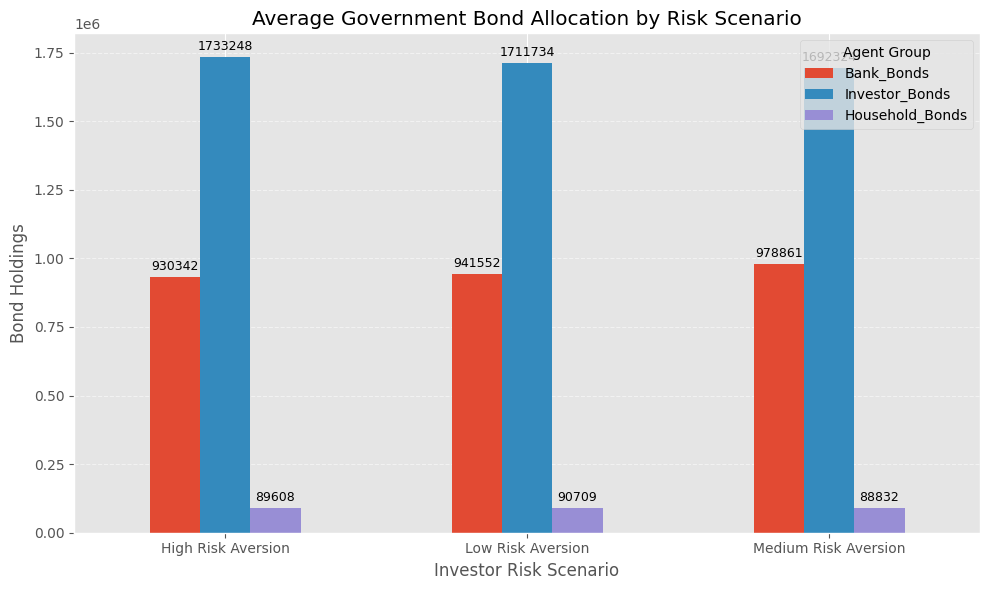

In [55]:
bond_columns = [
    "Bank_Bonds",
    "Investor_Bonds",
    "Household_Bonds"
]

bond_summary = (
    repeated_df
    .groupby("Scenario")[bond_columns]
    .mean()
)

ax = bond_summary.plot(
    kind="bar",
    figsize=(10, 6)
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.0f',
        padding=3,
        fontsize=9,
        rotation=0
    )

plt.title("Average Government Bond Allocation by Risk Scenario")
plt.xlabel("Investor Risk Scenario")
plt.ylabel("Bond Holdings")
plt.xticks(rotation=0)
plt.legend(title="Agent Group")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### **Coupon income comparison**

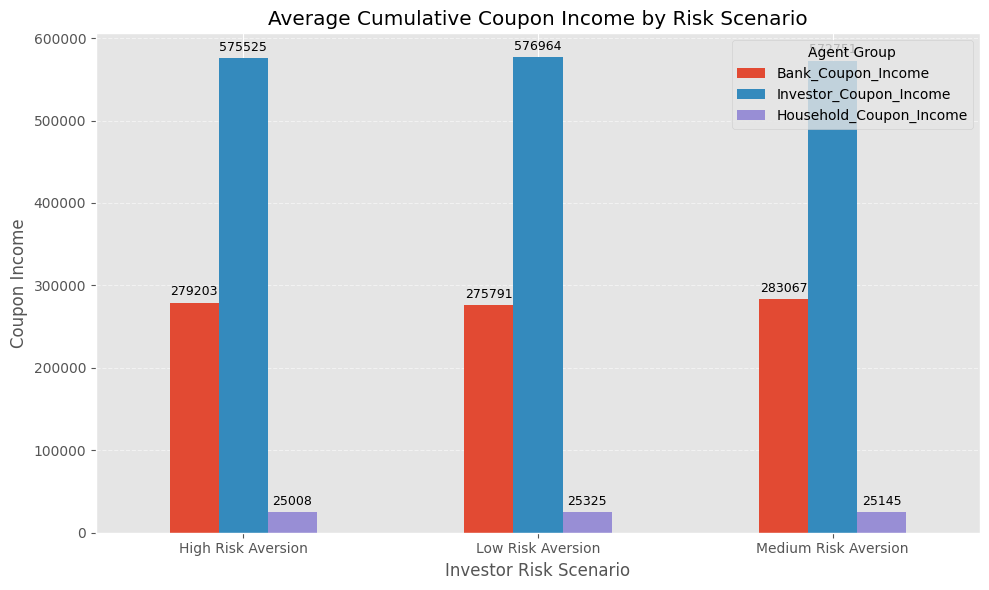

In [56]:
coupon_columns = [
    "Bank_Coupon_Income",
    "Investor_Coupon_Income",
    "Household_Coupon_Income"
]

coupon_summary = (
    repeated_df
    .groupby("Scenario")[coupon_columns]
    .mean()
)

ax = coupon_summary.plot(
    kind="bar",
    figsize=(10, 6)
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.0f',
        padding=3,
        fontsize=9,
        rotation=0
    )

plt.title("Average Cumulative Coupon Income by Risk Scenario")
plt.xlabel("Investor Risk Scenario")
plt.ylabel("Coupon Income")
plt.xticks(rotation=0)
plt.legend(title="Agent Group")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### **Wealth comparison**

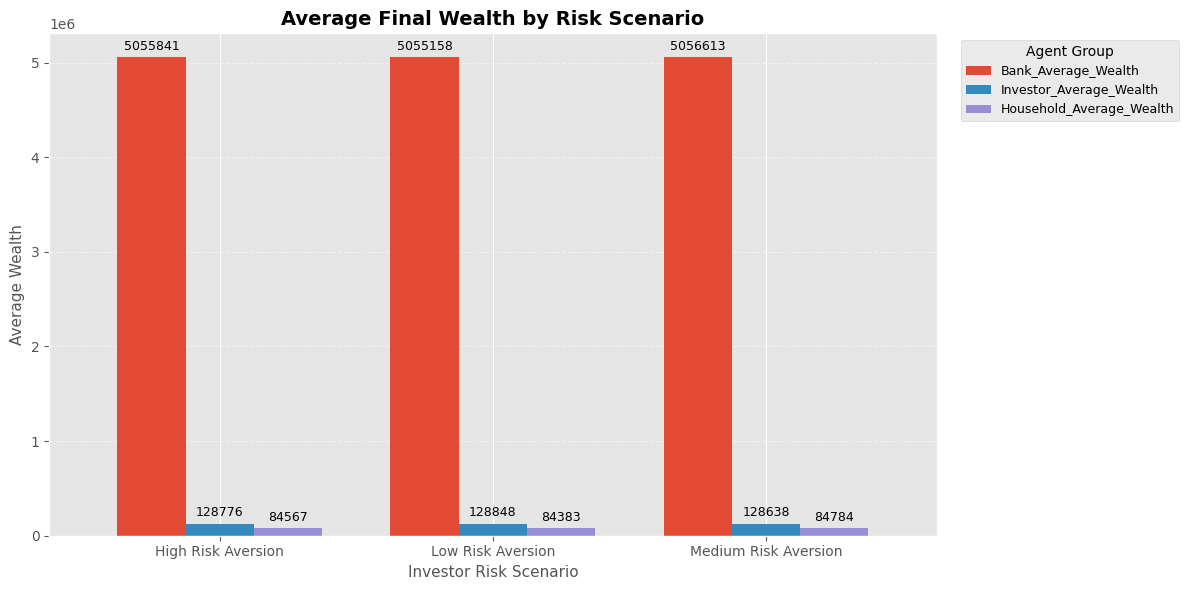

In [57]:
wealth_columns = [
    "Bank_Average_Wealth",
    "Investor_Average_Wealth",
    "Household_Average_Wealth"
]

wealth_summary = (
    repeated_df
    .groupby("Scenario")[wealth_columns]
    .mean()
)

fig, ax = plt.subplots(figsize=(12, 6))

wealth_summary.plot(
    kind="bar",
    ax=ax,
    width=0.75
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.0f',
        padding=3,
        fontsize=9,
        rotation=0
    )

ax.set_title(
    "Average Final Wealth by Risk Scenario",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Investor Risk Scenario",
    fontsize=11
)

ax.set_ylabel(
    "Average Wealth",
    fontsize=11
)

ax.tick_params(axis="x", rotation=0)

ax.legend(
    title="Agent Group",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=9,
    title_fontsize=10
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

ax.set_axisbelow(True)

fig.tight_layout()

plt.show()

### **Exporting experiment results**

In [58]:
# 1. Exporting individual evaluation results
repeated_df.to_csv(
    "Risk_Preference_Experiment_Results.csv",
    index=False
)

# 2. Exporting statistical summary
scenario_summary.to_csv(
    "Risk_Preference_Statistical_Summary.csv"
)

# 3. Exporting accounting verification by scenario
verification_df = (
    repeated_df
    .groupby("Scenario")["Accounting_Passed"]
    .agg(["count", "all"])
    .reset_index()
)

verification_df.columns = [
    "Scenario",
    "Simulation_Runs",
    "Accounting_Passed"
]

verification_df["Result"] = verification_df[
    "Accounting_Passed"
].map({
    True: "PASS",
    False: "FAIL"
})

verification_df.to_csv(
    "Risk_Preference_Verification.csv",
    index=False
)

# 4. Exporting detailed accounting verification
detailed_verification_df.to_csv(
    "Detailed_Accounting_Verification.csv",
    index=False
)

# 5. Exporting Q-learning training results
training_df.to_csv(
    "Q_Learning_Training_Results.csv",
    index=False
)

print("=" * 65)
print("EXPERIMENT RESULTS EXPORTED SUCCESSFULLY")
print("=" * 65)

print("\nExported files:")

exported_files = [
    "Risk_Preference_Experiment_Results.csv",
    "Risk_Preference_Statistical_Summary.csv",
    "Risk_Preference_Verification.csv",
    "Detailed_Accounting_Verification.csv",
    "Q_Learning_Training_Results.csv"
]

EXPERIMENT RESULTS EXPORTED SUCCESSFULLY

Exported files:
